# Linear Algebra for Data Science with NumPy and Pandas

One notebook, one dataset, one mini project. Every idea is shown first in plain words, then on a tiny example, then on real data.

## How to use this notebook

- Run the cells from top to bottom with `Shift+Enter`. Later parts reuse variables created in earlier parts.
- Change the numbers and run again. Experimenting is the fastest way to learn.
- Each part ends with a few exercises. Try them before looking at the solutions at the end of the notebook.

## Roadmap

| Part | Topic | The idea in one line |
|---|---|---|
| 0 | Setup and the dataset | Meet the data |
| 1 | NumPy basics | Grids of numbers and fast maths on them |
| 2 | Pandas basics | Tables with labelled columns |
| 3 | Vectors and matrices | Every row and every column of a table is a vector |
| 4 | Projection | The closest point on a line or plane |
| 5 | Least squares and linear regression | The best-fit line is a projection |
| 6 | Eigenvalues and diagonalization | Directions that a matrix only stretches |
| 7 | Special matrices, similarity and algorithms | Matrices with helpful structure, and how computers use them |
| 8 | Singular value decomposition (SVD) | A decomposition that works for every matrix |
| 9 | Mini project | Everything together on one question |

## The dataset

We use the Diabetes dataset that ships with scikit-learn, so no download is needed. It has 442 patients. For each patient there are 10 measurements taken at the start of a study, and one number that says how far the disease had progressed one year later.

# Part 0: Setup and the dataset

In [110]:
import numpy as np                              # arrays and linear algebra
import pandas as pd                             # tables with labelled columns
import matplotlib.pyplot as plt                 # plots
from sklearn.datasets import load_diabetes      # the dataset used in this notebook

# Display settings. They change how results look, not the results themselves
# NumPy: print 3 decimals, no scientific notation, and lines wide enough to keep 10 numbers on one row
np.set_printoptions(precision=3, suppress=True, linewidth=120)
pd.set_option('display.precision', 3)             # Pandas: show 3 decimals in tables
plt.rcParams['figure.figsize'] = (6, 4)           # default plot size: 6 wide and 4 high, in inches

In [111]:
# Load the data. as_frame=True gives a Pandas table, scaled=False keeps the original units
raw = load_diabetes(as_frame=True, scaled=False)

# raw.frame is the full table. rename gives the unclear column names readable ones (old name: new name)
df = raw.frame.rename(columns={
    's1': 'chol',
    's2': 'ldl',
    's3': 'hdl',
    's4': 'chol_hdl',
    's5': 'log_trig',
    's6': 'glucose',
    'target': 'progression',
})

print(df.shape)     # (number of rows, number of columns)
df.head()           # show the first 5 rows

(442, 11)


,age,sex,bmi,bp,chol,ldl,hdl,chol_hdl,log_trig,glucose,progression
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.860,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.892,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.673,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.890,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.290,80.0,135.0


The original column names `s1` to `s6` are hard to remember, so the cell above renames them.

| Column | Meaning |
|---|---|
| `age` | Age in years |
| `sex` | Coded 1 or 2 (the dataset does not say which is which) |
| `bmi` | Body mass index |
| `bp` | Average blood pressure |
| `chol` | Total cholesterol |
| `ldl` | LDL cholesterol |
| `hdl` | HDL cholesterol |
| `chol_hdl` | Total cholesterol divided by HDL |
| `log_trig` | Probably the log of the triglycerides level (the dataset notes are not certain) |
| `glucose` | Blood sugar level |
| `progression` | Disease progression one year later. This is the value we want to predict. |

# Part 1: NumPy basics

A NumPy **array** is a grid of numbers that all have the same type. Maths on an array happens on all the numbers at once, without writing a Python loop. That makes it short to write and fast to run.

## 1.1 Creating arrays

In [112]:
a = np.array([1, 2, 3, 4])            # a 1D array, made from a Python list
grid = np.array([[1, 2, 3],           # a 2D array, made from a list of lists:
                 [4, 5, 6]])          # each inner list becomes one row

print('a =', a)
# shape = size along each dimension, ndim = number of dimensions, dtype = type of the numbers
print('shape:', a.shape, ' dimensions:', a.ndim, ' type:', a.dtype)
print()                               # prints an empty line
print('grid =')
print(grid)
print('shape:', grid.shape, ' dimensions:', grid.ndim)

a = [1 2 3 4]
shape: (4,)  dimensions: 1  type: int64

grid =
[[1 2 3]
 [4 5 6]]
shape: (2, 3)  dimensions: 2


`shape` is the most useful thing to check. `(2, 3)` means 2 rows and 3 columns. When something goes wrong in linear algebra code, printing the shapes usually shows why.

In [113]:
print(np.zeros(3))              # 3 zeros
print(np.ones((2, 3)))          # ones in 2 rows and 3 columns
print(np.arange(0, 10, 2))      # start, stop (not included), step
print(np.linspace(0, 1, 5))     # 5 evenly spaced numbers from 0 to 1
print(np.eye(3))                # identity matrix: ones on the diagonal

[0. 0. 0.]
[[1. 1. 1.]
 [1. 1. 1.]]
[0 2 4 6 8]
[0.   0.25 0.5  0.75 1.  ]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


## 1.2 Arrays from our dataset

`.to_numpy()` turns Pandas data into a NumPy array. We make three arrays that the rest of the notebook keeps using:

- `X`: the 10 measurements for all patients
- `y`: the progression value for all patients
- `bmi`: one single measurement, handy for small examples

In [114]:
features = list(df.columns.drop('progression'))    # the 10 measurement names

X = df[features].to_numpy()            # 2D array: the 10 measurement columns
y = df['progression'].to_numpy()       # 1D array: the value we want to predict
bmi = df['bmi'].to_numpy()             # 1D array: just the bmi column

print(features)
print('X:  ', X.shape, '-> 442 patients (rows), 10 measurements (columns)')
print('y:  ', y.shape)
print('bmi:', bmi.shape)

['age', 'sex', 'bmi', 'bp', 'chol', 'ldl', 'hdl', 'chol_hdl', 'log_trig', 'glucose']
X:   (442, 10) -> 442 patients (rows), 10 measurements (columns)
y:   (442,)
bmi: (442,)


## 1.3 Indexing and slicing

- Counting starts at 0.
- For a 2D array write `X[row, column]`.
- `:` means everything, `:5` means the first 5, `-1` means the last one.

In [115]:
print('First patient:       ', X[0])        # row 0: all 10 measurements
print('BMI of first patient:', X[0, 2])     # row 0, column 2
print('First 5 BMI values:  ', X[:5, 2])    # rows 0 to 4, column 2
print('Age of last patient: ', X[-1, 0])    # last row, column 0
print('First 3 rows, first 4 columns:')
print(X[:3, :4])                            # rows 0 to 2, columns 0 to 3

First patient:        [ 59.     2.    32.1  101.   157.    93.2   38.     4.     4.86  87.  ]
BMI of first patient: 32.1
First 5 BMI values:   [32.1 21.6 30.5 25.3 23. ]
Age of last patient:  36.0
First 3 rows, first 4 columns:
[[ 59.    2.   32.1 101. ]
 [ 48.    1.   21.6  87. ]
 [ 72.    2.   30.5  93. ]]


You can also pick values with a condition. The condition makes an array of `True` and `False` (a mask), and the mask selects the matching entries.

In [116]:
high_bmi = bmi > 30          # compares every value with 30: True or False for each patient

print(high_bmi[:8])          # the first 8 answers
print('Patients with BMI over 30:   ', high_bmi.sum())      # True counts as 1
# y[high_bmi] keeps only the True positions. round(value, 2) keeps 2 decimals, so the output stays short
print('Their average progression:   ', round(y[high_bmi].mean(), 2))
print('Average for everyone else:   ', round(y[~high_bmi].mean(), 2))     # ~ means not

[ True False  True False False False False False]
Patients with BMI over 30:    95
Their average progression:    213.26
Average for everyone else:    135.4


## 1.4 Maths on whole arrays

Operations apply to every entry at once. This is called **vectorization**.

In [117]:
first = bmi[:5]          # the first 5 BMI values

print(first)
print(first + 1)         # add 1 to every value
print(first * 2)         # double every value
print(first ** 2)        # square every value
print(np.sqrt(first))    # square root of every value

[32.1 21.6 30.5 25.3 23. ]
[33.1 22.6 31.5 26.3 24. ]
[64.2 43.2 61.  50.6 46. ]
[1030.41  466.56  930.25  640.09  529.  ]
[5.666 4.648 5.523 5.03  4.796]


## 1.5 Summaries and the `axis` argument

For a 2D array you choose the direction of a summary:

- `axis=0` works down the rows and gives one answer per column.
- `axis=1` works across the columns and gives one answer per row.

In [118]:
# axis=0: average down each column, which gives 10 numbers
print('Mean of each column (axis=0):', X.mean(axis=0))
print('Shape with axis=0:', X.mean(axis=0).shape, '-> one number per measurement')
print('Shape with axis=1:', X.mean(axis=1).shape, '-> one number per patient')
# max, min and std (standard deviation: how spread out the values are) of a single column
print('Largest BMI:', bmi.max(), ' Smallest BMI:', bmi.min(), ' Spread (std):', round(bmi.std(), 3))

Mean of each column (axis=0): [ 48.518   1.468  26.376  94.647 189.14  115.439  49.788   4.07    4.641  91.26 ]
Shape with axis=0: (10,) -> one number per measurement
Shape with axis=1: (442,) -> one number per patient
Largest BMI: 42.2  Smallest BMI: 18.0  Spread (std): 4.413


## 1.6 Broadcasting

When two arrays have different shapes, NumPy stretches the smaller one to fit, if it can. `X` has shape `(442, 10)` and the column means have shape `(10,)`, so `X - col_means` subtracts each column's mean from every row.

- **Centering** means subtracting the mean, so each column has mean 0.
- **Standardizing** means also dividing by the standard deviation, so each column has mean 0 and spread 1. The measurements then share one scale, even though they started in different units.

We use the standardized table `Z` many times later.

In [119]:
col_means = X.mean(axis=0)         # the mean of each of the 10 columns
col_stds = X.std(axis=0)           # the standard deviation of each column

# Broadcasting: shapes (442, 10) and (10,), so the 10 means are subtracted from every row
X_centered = X - col_means
Z = X_centered / col_stds          # divide each column by its spread: standardized measurements

# np.allclose checks that numbers are equal, ignoring tiny rounding differences
print('Column means of Z are all 0:', np.allclose(Z.mean(axis=0), 0))
print('Column stds of Z: ', Z.std(axis=0))

Column means of Z are all 0: True
Column stds of Z:  [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 1.7 Reshaping and stacking

`reshape` changes the shape without changing the numbers. `np.column_stack` glues 1D arrays together as the columns of a 2D array. We need that in Part 5 to build the matrix for a best-fit line.

In [120]:
v = np.arange(6)            # the numbers 0 to 5
print(v)
print(v.reshape(2, 3))      # the same 6 numbers as 2 rows and 3 columns
print(v.reshape(-1, 1))     # one column; -1 means: work this size out for me

ones = np.ones(len(bmi))                    # 442 ones, one for each patient
stacked = np.column_stack([ones, bmi])      # put the two 1D arrays side by side as columns
print(stacked[:3])                          # the first 3 rows
print(stacked.shape)

[0 1 2 3 4 5]
[[0 1 2]
 [3 4 5]]
[[0]
 [1]
 [2]
 [3]
 [4]
 [5]]
[[ 1.  32.1]
 [ 1.  21.6]
 [ 1.  30.5]]
(442, 2)


## Exercises for Part 1

1. Make an array holding 10, 20, 30, up to 100, and print its shape.
2. Take the `age` column out of `X` (it is column 0). Find the youngest, oldest and average age.
3. How many patients are older than 60? What is their average `y`?
4. Standardize `y`: subtract its mean and divide by its standard deviation. Check that the result has mean 0 and standard deviation 1.

In [121]:
# Your code here


# Part 2: Pandas basics

Pandas adds labels on top of NumPy.

- A **DataFrame** is a table with named columns, like `df`.
- A **Series** is a single column of that table.

A good habit: use Pandas to load, clean and explore the data, then hand the numbers to NumPy for the linear algebra.

## 2.1 A first look

In [122]:
# For each column: its name, how many values are present, and the type of the values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          442 non-null    float64
 1   sex          442 non-null    float64
 2   bmi          442 non-null    float64
 3   bp           442 non-null    float64
 4   chol         442 non-null    float64
 5   ldl          442 non-null    float64
 6   hdl          442 non-null    float64
 7   chol_hdl     442 non-null    float64
 8   log_trig     442 non-null    float64
 9   glucose      442 non-null    float64
 10  progression  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [123]:
# describe() gives the count, mean, spread, smallest, largest and quartiles of every column
df.describe().T      # .T flips rows and columns so each measurement gets its own row

,count,mean,std,min,25%,50%,75%,max
age,442.0,48.518,13.109,19.000,38.250,50.00,59.000,79.000
sex,442.0,1.468,0.500,1.000,1.000,1.00,2.000,2.000
bmi,442.0,26.376,4.418,18.000,23.200,25.70,29.275,42.200
bp,442.0,94.647,13.831,62.000,84.000,93.00,105.000,133.000
chol,442.0,189.140,34.608,97.000,164.250,186.00,209.750,301.000
ldl,442.0,115.439,30.413,41.600,96.050,113.00,134.500,242.400
hdl,442.0,49.788,12.934,22.000,40.250,48.00,57.750,99.000
chol_hdl,442.0,4.070,1.290,2.000,3.000,4.00,5.000,9.090
log_trig,442.0,4.641,0.522,3.258,4.277,4.62,4.997,6.107
glucose,442.0,91.260,11.496,58.000,83.250,91.00,98.000,124.000


## 2.2 Selecting columns and rows

- `df['bmi']` gives one column (a Series).
- `df[['age', 'bmi']]` with a list gives several columns (a DataFrame).
- `df.iloc[...]` selects by position, like NumPy.
- `df.loc[...]` selects by label.

In [124]:
print(type(df['bmi']))                          # one column name gives a Series
df[['age', 'bmi', 'progression']].head(3)       # a list of names gives a DataFrame; head(3) shows 3 rows

<class 'pandas.core.series.Series'>


,age,bmi,progression
0,59.0,32.1,151.0
1,48.0,21.6,75.0
2,72.0,30.5,141.0


In [125]:
print(df.iloc[0, 2])            # by position: row 0, column 2
print(df.loc[0, 'bmi'])         # by label: row 0, column bmi
df.loc[0:4, ['age', 'bmi']]     # rows labelled 0 to 4; unlike NumPy, loc includes the end label

32.1
32.1


,age,bmi
0,59.0,32.1
1,48.0,21.6
2,72.0,30.5
3,24.0,25.3
4,50.0,23.0


## 2.3 Filtering rows

Put a condition inside the square brackets. Combine conditions with `&` (and), `|` (or) and `~` (not), and wrap each condition in round brackets.

In [126]:
# Keep only the rows where both conditions are True
older_high_bmi = df[(df['age'] > 60) & (df['bmi'] > 30)]

print(len(older_high_bmi), 'patients')      # len counts the rows
older_high_bmi.head()

21 patients


,age,sex,bmi,bp,chol,ldl,hdl,chol_hdl,log_trig,glucose,progression
2,72.0,2.0,30.5,93.00,156.0,93.6,41.0,4.0,4.673,85.0,141.0
23,61.0,2.0,32.0,103.67,210.0,85.2,35.0,6.0,6.107,124.0,245.0
44,61.0,2.0,32.7,97.00,177.0,118.4,29.0,6.0,4.997,87.0,259.0
85,61.0,1.0,33.0,95.00,182.0,114.8,54.0,3.0,4.190,74.0,141.0
91,61.0,1.0,31.2,79.00,235.0,156.8,47.0,5.0,5.050,96.0,164.0


## 2.4 Adding new columns

We work on a copy called `people` so that `df` stays unchanged for the later parts. `pd.cut` sorts numbers into bins.

In [127]:
people = df.copy()                  # an independent copy, so df itself is not changed

# Assigning to a new column name creates that column
people['age_group'] = pd.cut(
    people['age'],
    bins=[0, 40, 55, 100],                              # bin edges: up to 40, above 40 up to 55, above 55
    labels=['40 or under', '41 to 55', 'over 55'],      # one name for each bin
)
people['bmi_high'] = people['bmi'] > 30     # True or False for each patient

people[['age', 'age_group', 'bmi', 'bmi_high']].head()

,age,age_group,bmi,bmi_high
0,59.0,over 55,32.1,True
1,48.0,41 to 55,21.6,False
2,72.0,over 55,30.5,True
3,24.0,40 or under,25.3,False
4,50.0,41 to 55,23.0,False


## 2.5 Sorting and counting

`sort_values` orders the rows by a column, and `value_counts` counts how often each value occurs.

In [128]:
# Sort by progression, largest first, and show the top 5
people.sort_values('progression', ascending=False).head(5)

,age,sex,bmi,bp,chol,ldl,hdl,chol_hdl,log_trig,glucose,progression,age_group,bmi_high
256,35.0,1.0,41.3,81.0,168.0,102.8,37.0,5.0,4.949,94.0,346.0,40 or under,True
32,58.0,2.0,38.0,103.0,150.0,107.2,22.0,7.0,4.644,98.0,341.0,over 55,True
138,58.0,2.0,36.7,117.0,166.0,93.8,44.0,4.0,4.949,109.0,336.0,over 55,True
290,65.0,2.0,33.5,102.0,190.0,126.2,35.0,5.0,4.970,102.0,332.0,over 55,True
362,54.0,2.0,36.1,115.0,163.0,98.4,43.0,4.0,4.682,101.0,321.0,41 to 55,True


In [129]:
# value_counts counts how many rows have each value
print(people['age_group'].value_counts())
print()
print(people['sex'].value_counts())

age_group
41 to 55       177
over 55        143
40 or under    122
Name: count, dtype: int64

sex
1.0    235
2.0    207
Name: count, dtype: int64


## 2.6 Group by

`groupby` splits the rows into groups, calculates something for each group, and puts the answers together. `observed=True` tells Pandas to list only the groups that actually occur in the data.

In [130]:
# Split the rows by age_group, then take the mean of progression inside each group
people.groupby('age_group', observed=True)['progression'].mean()

age_group
40 or under    134.803
41 to 55       149.859
over 55        169.734
Name: progression, dtype: float64

In [131]:
# Group by two columns at once. agg calculates several summaries for each group
people.groupby(['age_group', 'bmi_high'], observed=True)['progression'].agg(['count', 'mean', 'std'])

count     mean     std
age_group   bmi_high                        
40 or under False        99  125.111  62.970
            True         23  176.522  79.537
41 to 55    False       139  129.986  73.720
            True         38  222.553  69.890
over 55     False       109  151.642  66.002
            True         34  227.735  68.560

## 2.7 Missing values

Real data often has gaps. This dataset has none, so we remove 20 BMI values on purpose in a copy called `messy`, just to practise.

In [132]:
# isna() marks every missing value as True. The first sum counts them per column, the second adds those up
print('Missing values in df:', df.isna().sum().sum())

messy = df.copy()
rng = np.random.default_rng(0)                              # random number generator; the 0 makes it repeatable
rows = rng.choice(len(messy), size=20, replace=False)       # pick 20 different row numbers at random
messy.loc[rows, 'bmi'] = np.nan         # NaN is how missing numbers are stored

print('Missing per column:')
print(messy.isna().sum().head(4))       # missing values per column (first 4 columns only)

Missing values in df: 0
Missing per column:
age     0
sex     0
bmi    20
bp      0
dtype: int64


In [133]:
dropped = messy.dropna()                                  # option 1: remove rows with gaps
filled = messy.fillna({'bmi': messy['bmi'].mean()})       # option 2: fill gaps with the average

print('Rows before:', len(messy), ' after dropna:', len(dropped))
print('Missing BMI after fillna:', filled['bmi'].isna().sum())

Rows before: 442  after dropna: 422
Missing BMI after fillna: 0


## 2.8 Correlation and quick plots

Correlation is a number from -1 to 1 that says how closely two columns move together. Near 1: they rise together. Near -1: one rises when the other falls. Near 0: no straight-line relationship.

In [134]:
# corr() gives the correlation of every column with every other column.
# We keep the progression column of that table and sort it from largest to smallest
df.corr()['progression'].sort_values(ascending=False)

progression    1.000
bmi            0.586
log_trig       0.566
bp             0.441
chol_hdl       0.430
glucose        0.382
chol           0.212
age            0.188
ldl            0.174
sex            0.043
hdl           -0.395
Name: progression, dtype: float64

`bmi` and `log_trig` are the measurements most strongly related to progression. In Part 3 you will see that correlation is the cosine of an angle between two vectors.

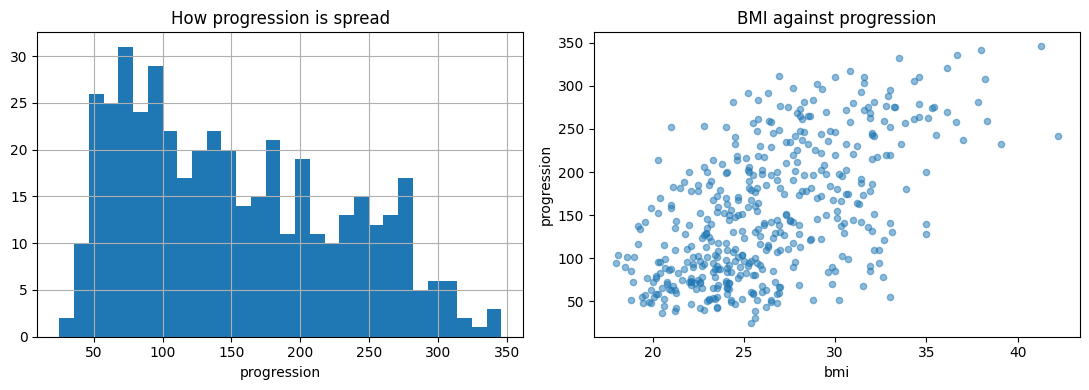

In [135]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))     # one figure with 2 plots side by side

# Left plot: a histogram counts how many patients fall in each of 30 value ranges
df['progression'].hist(bins=30, ax=axes[0])
axes[0].set_title('How progression is spread')
axes[0].set_xlabel('progression')

# Right plot: one dot per patient. alpha=0.5 makes the dots see-through
df.plot.scatter(x='bmi', y='progression', alpha=0.5, ax=axes[1])
axes[1].set_title('BMI against progression')

plt.tight_layout()      # stop the two plots from overlapping
plt.show()              # display the figure

## 2.9 Going back from NumPy to Pandas

`pd.DataFrame(array, columns=names)` wraps a NumPy array in a table again. Here we check the standardized table `Z` from Part 1.

In [136]:
# Wrap Z in a table again, summarize it, and keep only 4 of the summary columns
pd.DataFrame(Z, columns=features).describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
age,8.038e-18,1.001,-2.254,2.328
sex,1.608e-16,1.001,-0.939,1.065
bmi,1.005e-16,1.001,-1.898,3.586
bp,1.061e-15,1.001,-2.363,2.776
chol,-2.894e-16,1.001,-2.665,3.236
ldl,-1.246e-16,1.001,-2.431,4.179
hdl,-1.326e-16,1.001,-2.151,3.809
chol_hdl,-1.447e-16,1.001,-1.606,3.894
log_trig,2.251e-16,1.001,-2.651,2.809
glucose,2.371e-16,1.001,-2.896,2.851


The `std` column shows 1.001 instead of exactly 1. That is not a mistake: Pandas divides by `n - 1` when it calculates a standard deviation, while NumPy divides by `n`. With 442 rows the difference is tiny.

The `mean` column shows numbers like `1.6e-16`. That is scientific notation for an extremely small number (1 divided by 10 sixteen times), so read it as zero.

## Exercises for Part 2

1. Show the 5 youngest patients.
2. What is the average `bp` for each value of `sex`?
3. Add a column `bp_high` to `people` that is `True` when `bp` is above 100. How many patients have it?
4. Which two measurements (not counting `progression`) are most strongly correlated with each other?

In [137]:
# Your code here


# Part 3: Vectors and matrices

A **vector** is a list of numbers. Our table is full of them:

- Each **row** is a vector: one patient described by 10 numbers.
- Each **column** is a vector: one measurement across 442 patients.

A **matrix** is a grid of numbers, such as `X`. Linear algebra is the maths of vectors and matrices.

## 3.1 Adding, scaling and length

We start in 2D because it can be drawn. A vector with two numbers is an arrow from the origin.

In [138]:
a = np.array([3, 4])
b = np.array([4, 1])

print('a + b =', a + b)       # add matching entries
print('2 * a =', 2 * a)       # multiply every entry by 2
print('length of a =', np.linalg.norm(a))     # square root of 3*3 + 4*4

a + b = [7 5]
2 * a = [6 8]
length of a = 5.0


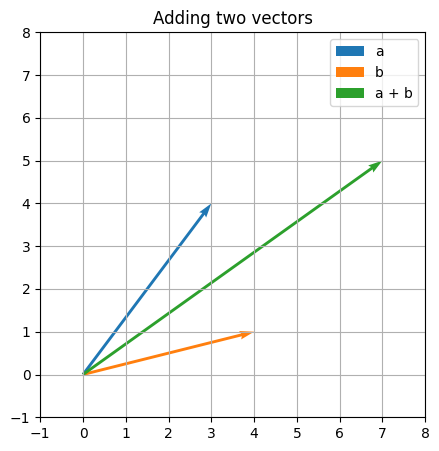

In [139]:
# A small helper that draws each vector as an arrow starting at the origin (0, 0)
def draw_vectors(vectors, labels, colors, limit=6):
    fig, ax = plt.subplots(figsize=(5, 5))
    for vec, label, color in zip(vectors, labels, colors):     # zip walks through the three lists together
        # quiver draws an arrow from (0, 0) to (vec[0], vec[1]). The settings angles, scale_units
        # and scale make the arrow match the numbers on the axes
        ax.quiver(0, 0, vec[0], vec[1], angles='xy', scale_units='xy', scale=1, color=color, label=label)
    ax.set_xlim(-1, limit)        # range shown on the horizontal axis
    ax.set_ylim(-1, limit)        # range shown on the vertical axis
    ax.set_aspect('equal')        # same scale on both axes, so angles look right
    ax.grid(True)                 # background grid
    ax.legend()                   # the box with the labels
    return ax

draw_vectors([a, b, a + b], ['a', 'b', 'a + b'], ['tab:blue', 'tab:orange', 'tab:green'], limit=8)
plt.title('Adding two vectors')
plt.show()

## 3.2 Dot product and angle

The **dot product** multiplies matching entries and adds the results. In NumPy it is written `a @ b`.

It is linked to the angle between the two vectors:

`a @ b = (length of a) × (length of b) × cos(angle)`

Two things to remember:

- If the dot product is 0, the vectors are **perpendicular** (also called orthogonal).
- The cosine is 1 when the vectors point the same way and -1 when they point in opposite ways.

In [140]:
print('a @ b =', a @ b)                 # 3*4 + 4*1

# The formula rearranged: cosine = dot product / (length of a * length of b)
cos_angle = (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))
print('cosine of the angle:', round(cos_angle, 4))
# arccos turns the cosine back into an angle (in radians); np.degrees converts it to degrees
print('angle in degrees:   ', round(np.degrees(np.arccos(cos_angle)), 2))

# 1*(-2) + 2*1 = 0
print('a perpendicular pair:', np.array([1, 2]) @ np.array([-2, 1]))

a @ b = 16
cosine of the angle: 0.7761
angle in degrees:    39.09
a perpendicular pair: 0


### Correlation is a cosine

Take two columns of the dataset, subtract the mean from each, and calculate the cosine of the angle between them. The result is their correlation.

In [141]:
bmi_c = bmi - bmi.mean()      # centered bmi
y_c = y - y.mean()            # centered progression

# The same cosine formula as above, now for two vectors with 442 entries each
cosine = (bmi_c @ y_c) / (np.linalg.norm(bmi_c) * np.linalg.norm(y_c))

print('cosine between the two centered columns:', round(cosine, 6))
print('correlation from Pandas:                ', round(df['bmi'].corr(df['progression']), 6))

cosine between the two centered columns: 0.58645
correlation from Pandas:                 0.58645


The two numbers match. Each column is an arrow in a space with 442 dimensions, and two columns are strongly correlated when their arrows point in nearly the same direction.

A computer stores decimal numbers with tiny rounding errors, so two results that should be equal can differ around the 15th digit. That is why the code in this notebook rounds numbers before printing them, and compares with `np.allclose` instead of `==`.

## 3.3 Matrices

- `A.T` is the **transpose**: rows become columns.
- `A @ x` multiplies a matrix by a vector.
- `A @ B` multiplies two matrices.
- `A * B` is something else: it multiplies entry by entry. Mixing up `*` and `@` is a very common beginner mistake.

In [142]:
A = np.array([[1, 2],
              [3, 4]])
B = np.array([[0, 1],
              [1, 0]])
x = np.array([1, 2])

print('A transpose:')
print(A.T)                    # row 0 becomes column 0, row 1 becomes column 1
print('A @ x =', A @ x)       # each entry is the dot product of one row of A with x
print('A @ B =')
print(A @ B)                  # each entry is the dot product of a row of A with a column of B
print('A * B (entry by entry, not matrix multiplication) =')
print(A * B)

A transpose:
[[1 3]
 [2 4]]
A @ x = [ 5 11]
A @ B =
[[2 1]
 [4 3]]
A * B (entry by entry, not matrix multiplication) =
[[0 2]
 [3 0]]


The most useful way to read `A @ x`: it is a **mix of the columns of A**. The numbers in `x` say how much of each column to take.

In [143]:
print('A @ x:                        ', A @ x)
# A[:, 0] is column 0 of A (all rows, column 0). x[0] and x[1] are the two numbers in x
print('1 * column 0  +  2 * column 1:', x[0] * A[:, 0] + x[1] * A[:, 1])

A @ x:                         [ 5 11]
1 * column 0  +  2 * column 1: [ 5 11]


Two rules for matrix multiplication:

- **Shapes must fit.** `(m, n) @ (n, p)` gives `(m, p)`. The two inner numbers must be equal.
- **Order matters.** `A @ B` is usually not the same as `B @ A`.

In [144]:
# np.array_equal checks whether two arrays hold exactly the same numbers
print('A @ B equals B @ A?', np.array_equal(A @ B, B @ A))
print('X.T has shape', X.T.shape, 'and X has shape', X.shape, 'so X.T @ X has shape', (X.T @ X).shape)

A @ B equals B @ A? False
X.T has shape (10, 442) and X has shape (442, 10) so X.T @ X has shape (10, 10)


## 3.4 Identity, inverse and solving equations

- The **identity matrix** `I` has ones on the diagonal and zeros elsewhere. Multiplying by it changes nothing.
- The **inverse** of `A` undoes `A`: `A @ A_inv = I`. Only square matrices can have one, and not all of them do.

Two equations with two unknowns can be written as `A @ x = b`:

```
2x +  y = 5
 x + 3y = 10
```

In [145]:
A = np.array([[2., 1.],       # the numbers in front of x and y, one row per equation
              [1., 3.]])      # (writing 2. instead of 2 makes the entries decimal numbers)
b = np.array([5., 10.])       # the right-hand sides of the two equations

A_inv = np.linalg.inv(A)      # the inverse of A
print('A @ A_inv =')
# Gives the identity matrix. Rounding and adding 0 tidy the result (a zero could otherwise print as -0.)
print(np.round(A @ A_inv, 10) + 0)

x = np.linalg.solve(A, b)     # find the x that makes A @ x equal to b
print('solution x =', x)
print('check: A @ x =', A @ x)    # should give b back

A @ A_inv =
[[1. 0.]
 [0. 1.]]
solution x = [1. 3.]
check: A @ x = [ 5. 10.]


Use `np.linalg.solve(A, b)` rather than `np.linalg.inv(A) @ b`. It is faster and more accurate.

## 3.5 Column space and rank

- The **column space** of `A` is every vector you can make as `A @ x`, in other words every mix of its columns.
- The **rank** counts how many columns bring a new direction. A column that is just a mix of the others adds nothing.

In [146]:
independent = np.array([[1, 0],
                        [0, 1],
                        [1, 1]])
copycat = np.array([[1, 2],
                    [2, 4],
                    [3, 6]])       # second column is 2 times the first

# matrix_rank counts the columns that bring a new direction
print('rank of independent:', np.linalg.matrix_rank(independent))
print('rank of copycat:    ', np.linalg.matrix_rank(copycat))
print('rank of X:          ', np.linalg.matrix_rank(X))

rank of independent: 2
rank of copycat:     1
rank of X:           10


`X` has rank 10, so none of the 10 measurements is an exact mix of the others. Some come close though (`chol` and `ldl` have correlation 0.90). That matters in Parts 5 and 8.

## Exercises for Part 3

1. For `u = [1, 2, 3]` and `v = [4, 5, 6]`, work out the dot product by hand, then check it with NumPy.
2. Find the angle in degrees between `u` and `v`.
3. Calculate the cosine between the centered `chol` and centered `ldl` columns. Compare it with `df['chol'].corr(df['ldl'])`.
4. Solve these two equations with NumPy: `x + 2y = 8` and `3x - y = 3`.

In [147]:
# Your code here


# Part 4: Projection

Projection answers one question: **what is the closest point to `b` that lies on a given line or plane?** Think of it as the shadow of `b`.

## 4.1 Projecting onto a line

Take the line through a vector `a`. Every point on it is a multiple of `a`. The closest point to `b` is

`p = x̂ · a`  with  `x̂ = (a @ b) / (a @ a)`

(`x̂` is read x-hat. In code we call it `x_hat`.)

The leftover part `e = b - p` is called the **error**. It is always perpendicular to `a`. That is what makes `p` the closest point.

In [148]:
a = np.array([4., 1.])
b = np.array([2., 3.])

x_hat = (a @ b) / (a @ a)     # how many times a we need to reach the closest point
p = x_hat * a                 # the closest point on the line: the projection of b
e = b - p                     # what is left over: the error

print('x_hat =', round(x_hat, 4))
print('projection p =', p)
print('error e =', e)
# round removes rounding leftovers, abs stops a zero from being printed as -0.0
print('e @ a =', abs(round(e @ a, 10)), '(zero means perpendicular)')

x_hat = 0.6471
projection p = [2.588 0.647]
error e = [-0.588  2.353]
e @ a = 0.0 (zero means perpendicular)


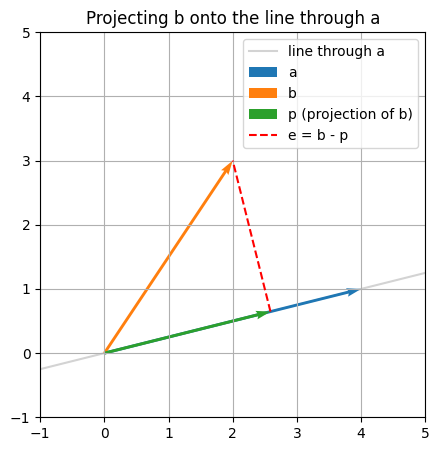

In [149]:
fig, ax = plt.subplots(figsize=(5, 5))
# The line through a, drawn between the points (-1, -0.25) and (5, 1.25):
# the first list holds the two x values, the second list the two y values.
# zorder=0 draws the line behind the arrows
ax.plot([-1, 5], [-0.25, 1.25], color='lightgray', label='line through a', zorder=0)
# Arrows for a, b and the projection p, all starting at (0, 0)
ax.quiver(0, 0, a[0], a[1], angles='xy', scale_units='xy', scale=1, color='tab:blue', label='a')
ax.quiver(0, 0, b[0], b[1], angles='xy', scale_units='xy', scale=1, color='tab:orange', label='b')
ax.quiver(0, 0, p[0], p[1], angles='xy', scale_units='xy', scale=1, color='tab:green', label='p (projection of b)')
# A red dashed line ('r--') from the tip of p to the tip of b: the error
ax.plot([p[0], b[0]], [p[1], b[1]], 'r--', label='e = b - p')
ax.set_title('Projecting b onto the line through a')
ax.set_xlim(-1, 5)
ax.set_ylim(-1, 5)
ax.set_aspect('equal')
ax.grid(True)
ax.legend()
plt.show()

## 4.2 The projection matrix

The same projection can be stored as a matrix `P`, so that `P @ b` gives the projection of any `b`:

`P = (a aᵀ) / (aᵀ a)`

Every projection matrix has two properties:

- `P @ P = P`: projecting a second time changes nothing, because the point is already on the line.
- `P.T = P`: it is symmetric.

In [150]:
P = np.outer(a, a) / (a @ a)      # np.outer(a, a) builds the matrix a aᵀ

print('P =')
print(P)
print('P @ b =', P @ b)                              # the same p as before
print('P @ P equals P:', np.allclose(P @ P, P))      # projecting twice changes nothing
print('P.T equals P:  ', np.allclose(P.T, P))

P =
[[0.941 0.235]
 [0.235 0.059]]
P @ b = [2.588 0.647]
P @ P equals P: True
P.T equals P:   True


## 4.3 Projecting onto a plane

Now put several vectors as the columns of a matrix `A`. We want the point `p = A @ x̂` in the column space of `A` that is closest to `b`.

The rule is the same as before: the error `b - A @ x̂` must be perpendicular to **every** column of `A`. Written with matrices:

`Aᵀ (b - A x̂) = 0`

which rearranges to the **normal equations**:

`Aᵀ A x̂ = Aᵀ b`

Solve them for `x̂`, then `p = A @ x̂`. The projection matrix is `P = A (Aᵀ A)⁻¹ Aᵀ`.

In [151]:
A = np.array([[1., 0.],
              [0., 1.],
              [1., 1.]])
b = np.array([1., 2., 6.])    # a point that is not on the plane made by the two columns of A

x_hat = np.linalg.solve(A.T @ A, A.T @ b)     # solve the normal equations for x_hat
p = A @ x_hat                                 # the closest point on the plane
e = b - p                                     # the error

print('x_hat =', x_hat)
print('p =', p)
print('e =', e)
print('A.T @ e =', np.round(A.T @ e, 10), '(the error is perpendicular to both columns)')

x_hat = [2. 3.]
p = [2. 3. 5.]
e = [-1. -1.  1.]
A.T @ e = [0. 0.] (the error is perpendicular to both columns)


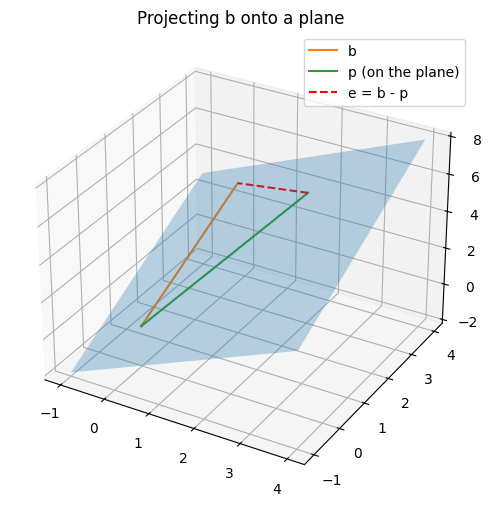

In [152]:
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection='3d')         # a 3D plot

# meshgrid makes a grid of (s, t) points. A @ [s, t] is the point (s, t, s + t), so that surface is the plane
s_grid, t_grid = np.meshgrid(np.linspace(-1, 4, 2), np.linspace(-1, 4, 2))
ax.plot_surface(s_grid, t_grid, s_grid + t_grid, alpha=0.3)      # the plane: every A @ x

# Each line joins two points: the three lists hold the x, y and z values of its two ends
ax.plot([0, b[0]], [0, b[1]], [0, b[2]], color='tab:orange', label='b')
ax.plot([0, p[0]], [0, p[1]], [0, p[2]], color='tab:green', label='p (on the plane)')
ax.plot([p[0], b[0]], [p[1], b[1]], [p[2], b[2]], 'r--', label='e = b - p')
ax.set_title('Projecting b onto a plane')
ax.legend()
plt.show()

In [153]:
P = A @ np.linalg.inv(A.T @ A) @ A.T      # the projection matrix formula from above

print('P =')
print(P)
print('P @ b =', P @ b)
print('P @ P equals P:', np.allclose(P @ P, P))

P =
[[ 0.667 -0.333  0.333]
 [-0.333  0.667  0.333]
 [ 0.333  0.333  0.667]]
P @ b = [2. 3. 5.]
P @ P equals P: True


## 4.4 Projection in our dataset: the mean

Take `y`, the 442 progression values, and project it onto the vector of all ones. The formula from 4.1 gives

`x̂ = (ones @ y) / (ones @ ones) = (sum of y) / 442`

which is the mean. So the mean is a projection: it is the single number that is closest to all the data at once.

In [154]:
ones = np.ones(len(y))                  # a vector of 442 ones
x_hat = (ones @ y) / (ones @ ones)      # ones @ y is the sum of y, and ones @ ones is 442

print('x_hat from the projection formula:', round(x_hat, 4))
print('mean of y:                        ', round(y.mean(), 4))

x_hat from the projection formula: 152.1335
mean of y:                         152.1335


## Exercises for Part 4

1. Project `b = [3, 4]` onto `a = [1, 0]`. Guess the answer before running the code.
2. Project `b = [1, 2, 3]` onto `a = [1, 1, 1]`, and check that the error is perpendicular to `a`.
3. Build `P` for the matrix whose columns are `[1, 1, 1]` and `[0, 1, 2]`. Check that `P @ P = P`, then project `b = [6, 0, 0]`.
4. Project the centered progression `y_c` onto the centered `bmi_c` (both were made in Part 3). What is `x_hat`? Remember the number: it comes back in Part 5.

In [155]:
# Your code here


# Part 5: Least squares and linear regression

We want a straight line that predicts progression from BMI:

`progression ≈ c + m × bmi`

Each patient gives one equation, so there are 442 equations but only 2 unknowns (`c` and `m`). No line passes through all 442 points, so `A @ x = b` has **no exact solution**.

**Least squares** picks the `x̂` that makes the total squared error as small as possible. That is the projection problem from Part 4: `A @ x̂` is the projection of `b` onto the column space of `A`, and the normal equations give `x̂`.

## 5.1 Fitting a line by hand

The matrix `A` has one row per patient and two columns: a column of ones (for `c`) and the BMI column (for `m`).

In [156]:
A = np.column_stack([np.ones(len(bmi)), bmi])     # column 0: ones, column 1: bmi
b = y                                             # the values we want the line to match

print('A has shape', A.shape)
print(A[:3])                                      # the first 3 rows

x_hat = np.linalg.solve(A.T @ A, A.T @ b)     # normal equations from Part 4
c, m = x_hat                                  # unpack the two numbers: intercept and slope

print('intercept c =', round(c, 3))
print('slope m     =', round(m, 3))

A has shape (442, 2)
[[ 1.  32.1]
 [ 1.  21.6]
 [ 1.  30.5]]
intercept c = -117.773
slope m     = 10.233


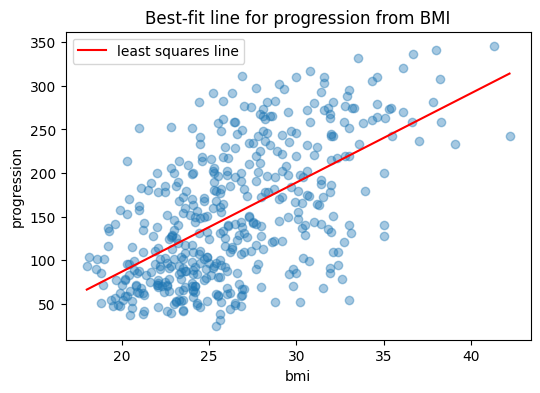

In [157]:
line_x = np.array([bmi.min(), bmi.max()])     # a straight line only needs its two end points

plt.scatter(bmi, y, alpha=0.4)                # one dot per patient
# The line: for each end point, the height is c + m * bmi
plt.plot(line_x, c + m * line_x, color='red', label='least squares line')
plt.title('Best-fit line for progression from BMI')
plt.xlabel('bmi')
plt.ylabel('progression')
plt.legend()
plt.show()

The slope is about 10: on average, one extra point of BMI goes with about 10 extra points of progression. It is the same number as the answer to exercise 4 of Part 4.

## 5.2 The errors are perpendicular to the columns of A

The differences between the real values and the predictions are called **residuals**. They are the error vector `e` from Part 4, so `A.T @ residuals` must be zero.

In [158]:
predictions = A @ x_hat           # the value on the line for every patient
residuals = b - predictions       # actual value minus predicted value

# A.T @ residuals holds the dot product of each column of A with the residuals
print('A.T @ residuals =', np.round(A.T @ residuals, 6))
# A vector dotted with itself is the sum of its squared entries
print('sum of squared errors:', round(residuals @ residuals))

A.T @ residuals = [0. 0.]
sum of squared errors: 1719582


Each zero has a meaning:

- Perpendicular to the ones column: the residuals add up to zero, so the line is not too high or too low overall.
- Perpendicular to the BMI column: nothing is left in the residuals that BMI could still explain.

## 5.3 Three ways to get the same answer

In practice you do not write out the normal equations. `np.linalg.lstsq` and scikit-learn solve the same problem.

`np.linalg.lstsq` returns four things. `[0]` picks the first one, which is the solution. `rcond=None` just selects the default setting.

In [159]:
from sklearn.linear_model import LinearRegression

by_lstsq = np.linalg.lstsq(A, b, rcond=None)[0]       # NumPy's least squares solver

# scikit-learn wants the inputs as a 2D table, so reshape turns bmi into a single column.
# It adds the ones column by itself, and stores the intercept and the slope separately
model = LinearRegression().fit(bmi.reshape(-1, 1), y)
by_sklearn = np.array([model.intercept_, model.coef_[0]])

print('normal equations:', x_hat)
print('np.linalg.lstsq: ', by_lstsq)
print('scikit-learn:    ', by_sklearn)

normal equations: [-117.773   10.233]
np.linalg.lstsq:  [-117.773   10.233]
scikit-learn:     [-117.773   10.233]


## 5.4 How good is the fit?

**R²** (R squared) compares the model with the simplest possible guess, which is to predict the mean for everyone:

`R² = 1 - (squared error of the model) / (squared error of guessing the mean)`

- 0 means no better than guessing the mean.
- 1 means perfect predictions.

In [160]:
def r_squared(actual, predicted):
    error_model = np.sum((actual - predicted) ** 2)         # squared error of the model
    error_mean = np.sum((actual - actual.mean()) ** 2)      # squared error of always guessing the mean
    return 1 - error_model / error_mean

print('R squared with bmi only:', round(r_squared(y, predictions), 4))
print('correlation squared:    ', round(df['bmi'].corr(df['progression']) ** 2, 4))

R squared with bmi only: 0.3439
correlation squared:     0.3439


BMI alone explains about a third of the variation in progression. With a single measurement, R² is the correlation squared, which is the squared cosine from Part 3.

## 5.5 Using all 10 measurements

Nothing changes in the method. `A` just gets more columns: the ones column plus all 10 measurements.

In [161]:
A_full = np.column_stack([np.ones(len(X)), X])        # ones column + 10 measurements: shape (442, 11)
coef = np.linalg.lstsq(A_full, y, rcond=None)[0]      # 11 numbers: the intercept and one per measurement

pred_full = A_full @ coef                             # predictions for all patients
print('R squared with all 10 measurements:', round(r_squared(y, pred_full), 4))

pd.Series(coef, index=['intercept'] + features)       # label each coefficient with its name

R squared with all 10 measurements: 0.5177


intercept   -334.567
age           -0.036
sex          -22.860
bmi            5.603
bp             1.117
chol          -1.090
ldl            0.746
hdl            0.372
chol_hdl       6.534
log_trig      68.483
glucose        0.280
dtype: float64

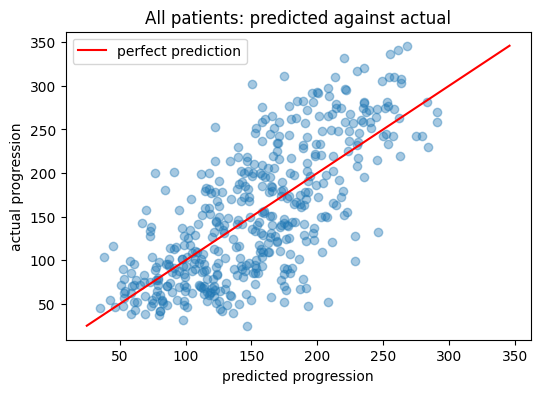

In [162]:
plt.scatter(pred_full, y, alpha=0.4)      # predicted value across, actual value up
# The red diagonal marks where predicted = actual. The closer the dots are to it, the better
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', label='perfect prediction')
plt.xlabel('predicted progression')
plt.ylabel('actual progression')
plt.title('All patients: predicted against actual')
plt.legend()
plt.show()

R² rises to about 0.52. The coefficients above are hard to compare, because each measurement has its own units. Fitting on the standardized table `Z` puts them on one scale: each coefficient then says how much progression changes when that measurement goes up by one standard deviation while the other measurements stay the same.

In [163]:
A_std = np.column_stack([np.ones(len(Z)), Z])             # like A_full, but built from the standardized table Z
coef_std = np.linalg.lstsq(A_std, y, rcond=None)[0]

print('R squared (unchanged by standardizing):', round(r_squared(y, A_std @ coef_std), 4))
# [1:] skips the intercept. sort_values orders the coefficients from smallest to largest
pd.Series(coef_std[1:], index=features).sort_values()

R squared (unchanged by standardizing): 0.5177


chol       -37.680
sex        -11.407
age         -0.476
glucose      3.217
hdl          4.806
chol_hdl     8.422
bp          15.429
ldl         22.676
bmi         24.727
log_trig    35.734
dtype: float64

`log_trig` and `bmi` have large positive coefficients, as the correlations in Part 2 suggested.

Look at `chol` and `ldl`: one large negative coefficient and one large positive one. These two columns are nearly copies of each other (correlation 0.90), so the model has trouble telling them apart and the two coefficients partly cancel. Be careful when reading meaning into coefficients of strongly correlated columns.

## 5.6 A warning about the normal equations

The **condition number** of a matrix says how much small rounding errors can grow during a calculation. Bigger is worse.

In [164]:
# np.linalg.cond calculates the condition number; round turns it into a whole number
print('condition number of A_full:           ', round(np.linalg.cond(A_full)))
print('condition number of A_full.T @ A_full:', round(np.linalg.cond(A_full.T @ A_full)))
print('condition number of A_std:            ', round(np.linalg.cond(A_std)))

condition number of A_full:            7236
condition number of A_full.T @ A_full: 52365337
condition number of A_std:             22


Forming `Aᵀ A` squares the condition number. So:

- Use the normal equations to **understand** least squares.
- Use `np.linalg.lstsq` to **calculate** it. It avoids `Aᵀ A` by using the SVD from Part 8.
- Standardizing the columns first also helps a lot, as the third number shows.

## Exercises for Part 5

1. Fit progression from `bp` alone. What are the slope and R²?
2. Fit progression from `bmi` and `bp` together (so `A` has 3 columns). Is R² higher than with `bmi` alone?
3. Check that the residuals of the full model are perpendicular to every column of `A_full`.
4. Use `c` and `m` from 5.1 to predict the progression of a new patient with a BMI of 30.

In [165]:
# Your code here


# Part 6: Eigenvalues and diagonalization

Multiplying a vector by a square matrix usually changes both its length and its direction. For a few special directions, the matrix only stretches the vector:

`A @ v = λ × v`

- `v` is an **eigenvector**: a direction the matrix does not turn.
- `λ` (lambda) is its **eigenvalue**: the stretch factor.

## 6.1 Seeing it

In [166]:
A = np.array([[2., 1.],
              [1., 2.]])

v1 = np.array([1., 1.])      # an eigenvector
v2 = np.array([1., -1.])     # another eigenvector
w = np.array([1., 0.])       # not an eigenvector

print('A @ v1 =', A @ v1, ' which is 3 times v1')
print('A @ v2 =', A @ v2, ' which is 1 times v2')
print('A @ w  =', A @ w, ' which points in a new direction')

A @ v1 = [3. 3.]  which is 3 times v1
A @ v2 = [ 1. -1.]  which is 1 times v2
A @ w  = [2. 1.]  which points in a new direction


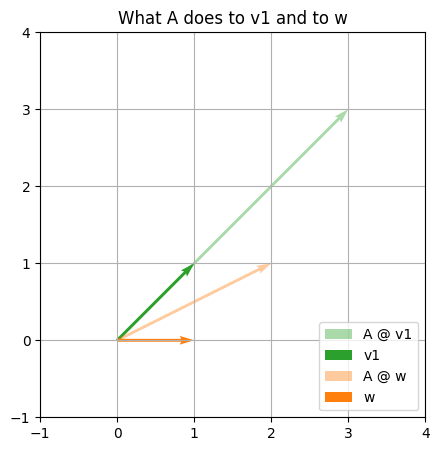

In [167]:
fig, ax = plt.subplots(figsize=(5, 5))
# Draw v1 and w (solid arrows) and what A turns them into (pale arrows)
for vec, color, name in [(v1, 'tab:green', 'v1'), (w, 'tab:orange', 'w')]:
    out = A @ vec             # the vector after multiplying by A
    ax.quiver(0, 0, out[0], out[1], angles='xy', scale_units='xy', scale=1,
              color=color, alpha=0.4, label='A @ ' + name)
    ax.quiver(0, 0, vec[0], vec[1], angles='xy', scale_units='xy', scale=1, color=color, label=name)
ax.set_title('What A does to v1 and to w')
ax.set_xlim(-1, 4)
ax.set_ylim(-1, 4)
ax.set_aspect('equal')
ax.grid(True)
ax.legend(loc='lower right')
plt.show()

The green arrow keeps its direction and only gets longer. The orange arrow is turned.

## 6.2 Finding them with NumPy

`np.linalg.eig` calculates the eigenvalues and eigenvectors of a square matrix.

In [168]:
# np.linalg.eig returns two things: the eigenvalues, and a matrix with one eigenvector in each column
eigenvalues, eigenvectors = np.linalg.eig(A)

print('eigenvalues:', eigenvalues)
print('eigenvectors (one per COLUMN):')
print(eigenvectors)

eigenvalues: [3. 1.]
eigenvectors (one per COLUMN):
[[ 0.707 -0.707]
 [ 0.707  0.707]]


Two things to know about the output:

- The eigenvectors are the **columns** of the second result, not the rows.
- NumPy scales each eigenvector to length 1, so `[1, 1]` shows up as `[0.707, 0.707]`. Any multiple of an eigenvector is still an eigenvector, including the one with flipped signs.

In [169]:
# Check A @ v = lambda * v for each of the 2 pairs
for i in range(2):
    value = eigenvalues[i]            # eigenvalue number i
    vector = eigenvectors[:, i]       # its eigenvector: column i
    print('A @ v =', A @ vector, '   lambda * v =', value * vector)

print('sum of eigenvalues:', eigenvalues.sum(), '  trace of A (sum of the diagonal):', np.trace(A))
print('product of eigenvalues:', round(eigenvalues.prod(), 6), '  determinant of A:', round(np.linalg.det(A), 6))

A @ v = [2.121 2.121]    lambda * v = [2.121 2.121]
A @ v = [-0.707  0.707]    lambda * v = [-0.707  0.707]
sum of eigenvalues: 4.0   trace of A (sum of the diagonal): 4.0
product of eigenvalues: 3.0   determinant of A: 3.0


The last two lines are a quick check that always works: the eigenvalues add up to the trace and multiply to the determinant. (The determinant is a single number calculated from a square matrix. It is 0 exactly when the matrix has no inverse.)

## 6.3 Diagonalization

Put the eigenvectors in the columns of a matrix `P` and the eigenvalues on the diagonal of a matrix `D`. Then

`A = P D P⁻¹`

Read it from right to left: switch to eigenvector coordinates, stretch each coordinate by its eigenvalue, switch back. In eigenvector coordinates, `A` is just a diagonal matrix.

In [170]:
P = eigenvectors                # the eigenvectors, one in each column
D = np.diag(eigenvalues)        # np.diag puts the eigenvalues on the diagonal of a matrix

print('D =')
print(D)
print('P @ D @ P_inv =')
print(P @ D @ np.linalg.inv(P))     # multiplying the three parts gives A back

D =
[[3. 0.]
 [0. 1.]]
P @ D @ P_inv =
[[2. 1.]
 [1. 2.]]


One reason this is useful: powers become easy. Multiplying `A` by itself `k` times gives `P Dᵏ P⁻¹`, and a power of a diagonal matrix is just each diagonal entry raised to that power.

In [171]:
k = 10

# Only the eigenvalues are raised to the power k
with_eigen = P @ np.diag(eigenvalues ** k) @ np.linalg.inv(P)
# For comparison: A multiplied by itself k times
direct = np.linalg.matrix_power(A, k)

print('with the eigenvalues:')
print(with_eigen)
print('multiplied out directly:')
print(direct)

with the eigenvalues:
[[29525. 29524.]
 [29524. 29525.]]
multiplied out directly:
[[29525. 29524.]
 [29524. 29525.]]


## 6.4 Example: what happens in the long run

This small example uses made-up numbers, not the dataset. Suppose that every year:

- 90% of people in a healthy weight range stay there and 10% move to a high range.
- 20% of people in the high range move back and 80% stay.

What share ends up in each group after many years?

In [172]:
T = np.array([[0.9, 0.2],
              [0.1, 0.8]])       # column 0: from healthy, column 1: from high

state = np.array([0.5, 0.5])    # start with half in each group
for year in range(50):          # repeat 50 times
    state = T @ state           # one year passes: T moves people between the two groups
print('after 50 years:', state)

t_values, t_vectors = np.linalg.eig(T)
print('eigenvalues:', t_values)

# np.argmax gives the position of the largest eigenvalue, which is the eigenvalue 1
steady = t_vectors[:, np.argmax(t_values)]     # the eigenvector for eigenvalue 1
steady = steady / steady.sum()                 # scale so the shares add up to 1
print('eigenvector for eigenvalue 1:', steady)

after 50 years: [0.667 0.333]
eigenvalues: [1.  0.7]
eigenvector for eigenvalue 1: [0.667 0.333]


The long-run split is the eigenvector with eigenvalue 1: multiplying by `T` no longer changes it. The other eigenvalue is 0.7, and its part shrinks by a factor of 0.7 every year until it is gone.

## 6.5 Not every matrix can be diagonalized

Diagonalization needs enough eigenvectors pointing in different directions to fill the matrix `P`. Some matrices do not have them.

In [173]:
shear = np.array([[1., 1.],
                  [0., 1.]])

shear_values, shear_vectors = np.linalg.eig(shear)     # eigenvalues, and eigenvectors in the columns
print('eigenvalues:', shear_values)
print('eigenvectors:')
print(shear_vectors)

eigenvalues: [1. 1.]
eigenvectors:
[[ 1. -1.]
 [ 0.  0.]]


Both columns lie on the same line, so `P` has no inverse and this matrix cannot be diagonalized. Part 7 has good news: **symmetric** matrices never have this problem.

## 6.6 Eigenvectors in our dataset

Take two standardized columns, `bmi` and `bp`. The small matrix `two.T @ two / n` holds how they vary together. For standardized columns it is their correlation matrix.

- Its eigenvectors point along the directions where the cloud of points is most and least spread out.
- Its eigenvalues are the amounts of spread (variance) along those directions.

In [174]:
# features.index('bmi') gives the column number of bmi. Z[:, [i, j]] keeps all rows of those two columns
two = Z[:, [features.index('bmi'), features.index('bp')]]
C2 = two.T @ two / len(two)     # 2 by 2 matrix: how the two columns vary together
print('correlation matrix of bmi and bp:')
print(C2)

c2_values, c2_vectors = np.linalg.eigh(C2)      # eigh is the version for symmetric matrices
print('eigenvalues:', c2_values)

correlation matrix of bmi and bp:
[[1.    0.395]
 [0.395 1.   ]]
eigenvalues: [0.605 1.395]


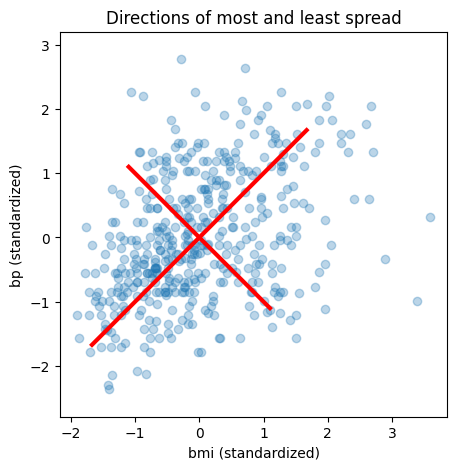

In [175]:
plt.figure(figsize=(5, 5))
plt.scatter(two[:, 0], two[:, 1], alpha=0.3)          # bmi across, bp up
# c2_vectors.T turns the columns into rows, so the loop gets one eigenvector at a time, with its eigenvalue
for value, vector in zip(c2_values, c2_vectors.T):
    half = vector * 2 * np.sqrt(value)           # a longer line means more spread in that direction
    # A line through the centre, from -half to +half
    plt.plot([-half[0], half[0]], [-half[1], half[1]], color='red', linewidth=3)
plt.title('Directions of most and least spread')
plt.xlabel('bmi (standardized)')
plt.ylabel('bp (standardized)')
plt.axis('equal')     # same scale on both axes, so the two lines look perpendicular
plt.show()

The long red line follows the direction in which the points are most spread out, and the short one is perpendicular to it. They are drawn as lines through the centre because an eigenvector and its opposite describe the same direction. Finding these directions for all 10 measurements is called principal component analysis (PCA). We get there in Part 8.

## Exercises for Part 6

1. Find the eigenvalues and eigenvectors of `[[4, 1], [2, 3]]`. Check `A @ v = λ × v` for each pair.
2. Use diagonalization to raise that matrix to the power 5. Compare with `np.linalg.matrix_power`.
3. In the example of 6.4, let 30% of the high group move back each year instead of 20%. What is the new long-run split?
4. Build the 2 by 2 correlation matrix for `chol` and `ldl`, as in 6.6. What are its eigenvalues, and why is one of them so small?

In [176]:
# Your code here


# Part 7: Special matrices, similarity and algorithms

Some matrices have a structure that makes them easy to work with. Most of numerical linear algebra is about rewriting a general matrix as a product of these special ones.

| Type | Rule | Why it helps |
|---|---|---|
| Diagonal | Zeros everywhere off the diagonal | Multiplying, inverting and taking powers work entry by entry |
| Triangular | Zeros below the diagonal (upper) or above it (lower) | Equations are solved by simple substitution; the eigenvalues sit on the diagonal |
| Symmetric | `S = Sᵀ` | Real eigenvalues and perpendicular eigenvectors |
| Orthogonal | `Qᵀ Q = I` | The inverse is just the transpose; lengths and angles are kept |
| Positive definite | Symmetric with all eigenvalues above 0 | `xᵀ S x` is positive for every nonzero `x`; `Aᵀ A` is of this type when the columns of `A` are independent |

## 7.1 Symmetric matrices

The correlation matrix of our 10 measurements is symmetric: the correlation of `bmi` with `bp` equals the correlation of `bp` with `bmi`. We can build it from the standardized table as `Z.T @ Z / n`.

In [177]:
C = Z.T @ Z / len(Z)          # 10 by 10 correlation matrix

print('shape:', C.shape)
print('symmetric:', np.allclose(C, C.T))      # symmetric means C equals its own transpose
print('same as the Pandas correlation table:', np.allclose(C, df[features].corr().to_numpy()))

shape: (10, 10)
symmetric: True
same as the Pandas correlation table: True


In [178]:
eigvals_C, eigvecs_C = np.linalg.eigh(C)      # eigh returns the eigenvalues sorted from small to large

print('eigenvalues:', eigvals_C)
# Q.T @ Q equal to the identity means: perpendicular columns, each of length 1
print('eigenvectors are perpendicular with length 1:', np.allclose(eigvecs_C.T @ eigvecs_C, np.eye(10)))
# Rebuild C from its eigenvectors (Q) and its eigenvalues (on the diagonal of D)
print('C equals Q @ D @ Q.T:', np.allclose(eigvecs_C @ np.diag(eigvals_C) @ eigvecs_C.T, C))

eigenvalues: [0.009 0.078 0.434 0.537 0.603 0.662 0.955 1.206 1.492 4.024]
eigenvectors are perpendicular with length 1: True
C equals Q @ D @ Q.T: True


This is the **spectral theorem**: every symmetric matrix can be written as `S = Q Λ Qᵀ`, where `Q` holds perpendicular eigenvectors of length 1 and `Λ` is diagonal. It is the diagonalization from Part 6, with the bonus that the inverse of `Q` is simply its transpose.

## 7.2 Orthogonal matrices

A square matrix is orthogonal when its columns are perpendicular to each other and have length 1. Multiplying by it turns or flips vectors without changing their length. A rotation is the standard example.

In [179]:
angle = np.radians(30)        # 30 degrees in radians, because np.cos and np.sin expect radians
# The matrix that turns every vector by that angle
rotation = np.array([[np.cos(angle), -np.sin(angle)],
                     [np.sin(angle),  np.cos(angle)]])

v = np.array([3., 4.])

print('rotation.T @ rotation =')
print(rotation.T @ rotation)
print('length before:', np.linalg.norm(v), '  length after:', np.linalg.norm(rotation @ v))

rotation.T @ rotation =
[[1. 0.]
 [0. 1.]]
length before: 5.0   length after: 5.0


## 7.3 Positive definite matrices

All eigenvalues of `C` above are positive, so `C` is positive definite. That means `x @ C @ x` is positive for any nonzero `x`.

Any matrix of the form `Aᵀ A` is at least positive **semi**definite (the result can be 0 but never negative), because `xᵀ Aᵀ A x` is the squared length of `A @ x`.

In [180]:
rng = np.random.default_rng(1)

for _ in range(4):                      # try 4 times (_ is a name for a counter we do not use)
    x = rng.normal(size=10)             # a random vector
    print('x @ C @ x =', round(x @ C @ x, 3))

x @ C @ x = 7.145
x @ C @ x = 2.969
x @ C @ x = 20.03
x @ C @ x = 12.063


## 7.4 Triangular matrices

The eigenvalues of a triangular matrix can be read straight off its diagonal.

In [181]:
upper = np.array([[2., 5., 1.],
                  [0., 3., 7.],
                  [0., 0., 4.]])

print('diagonal:   ', np.diag(upper))               # given a matrix, np.diag reads off its diagonal
print('eigenvalues:', np.linalg.eigvals(upper))     # eigvals returns only the eigenvalues

diagonal:    [2. 3. 4.]
eigenvalues: [2. 3. 4.]


## 7.5 Similar matrices

Two matrices `A` and `B` are **similar** when `B = M⁻¹ A M` for some invertible matrix `M`.

They describe the same transformation, seen in different coordinates. So they share everything that does not depend on the coordinates: eigenvalues, trace, determinant and rank.

Diagonalization is the best case of this. `D = P⁻¹ A P` says that `A` is similar to a diagonal matrix, and the eigenvectors are the coordinates that make it so.

In [182]:
A = np.array([[2., 1.],
              [1., 2.]])
M = np.array([[1., 2.],
              [0., 1.]])

B = np.linalg.inv(M) @ A @ M      # B is similar to A

print('B =')
print(B)
# np.sort puts the eigenvalues in increasing order, so the two lists are easy to compare
print('eigenvalues of A:', np.sort(np.linalg.eigvals(A)), '  of B:', np.sort(np.linalg.eigvals(B)))
print('trace of A:', np.trace(A), '  of B:', np.trace(B))
print('determinant of A:', round(np.linalg.det(A), 6), '  of B:', round(np.linalg.det(B), 6))

B =
[[ 0. -3.]
 [ 1.  4.]]
eigenvalues of A: [1. 3.]   of B: [1. 3.]
trace of A: 4.0   of B: 4.0
determinant of A: 3.0   of B: 3.0


`B` looks nothing like `A`, yet the eigenvalues, trace and determinant are identical.

## 7.6 Algorithms: how computers do the work

Computers almost never calculate an inverse. They **factor** a matrix into special matrices from the table at the top of this part, and then work with those.

| Factorization | Form | Used for |
|---|---|---|
| LU | `A = P L U` (permutation, lower, upper triangular) | Solving square systems; this is behind `np.linalg.solve` |
| QR | `A = Q R` (orthogonal columns, upper triangular) | Least squares |
| Cholesky | `S = L Lᵀ` (lower triangular) | Systems with a positive definite matrix |
| Eigen | `S = Q Λ Qᵀ` | Symmetric matrices |
| SVD | `A = U Σ Vᵀ` | Any matrix at all (Part 8) |

### LU factorization

This is elimination, the method for solving equations by hand, written as matrices.

In [183]:
from scipy.linalg import lu

A = np.array([[2., 1., 1.],
              [4., 3., 3.],
              [8., 7., 9.]])

perm, lower, upper = lu(A)      # three matrices: row reordering, lower triangular, upper triangular

print('lower triangular L:')
print(lower)
print('upper triangular U:')
print(upper)
print('perm @ L @ U equals A:', np.allclose(perm @ lower @ upper, A))

lower triangular L:
[[1.    0.    0.   ]
 [0.25  1.    0.   ]
 [0.5   0.667 1.   ]]
upper triangular U:
[[ 8.     7.     9.   ]
 [ 0.    -0.75  -1.25 ]
 [ 0.     0.    -0.667]]
perm @ L @ U equals A: True


`perm` only changes the order of the rows. Once `L` and `U` are known, solving `A @ x = b` takes two quick rounds of substitution.

### QR factorization by Gram-Schmidt

The Gram-Schmidt method turns the columns of `A` into perpendicular vectors of length 1, using projection from Part 4:

1. Take the next column.
2. Subtract its projections onto the columns already done. What is left is perpendicular to all of them.
3. Scale what is left to length 1.

The new columns form `Q`. The numbers used along the way form the upper triangular `R`.

In [184]:
def gram_schmidt(A):
    n_rows, n_cols = A.shape
    Q = np.zeros((n_rows, n_cols))           # an empty Q, filled in one column at a time
    R = np.zeros((n_cols, n_cols))           # an empty R
    for j in range(n_cols):                  # go through the columns of A
        v = A[:, j].copy()                   # step 1: take the next column
        for i in range(j):                   # step 2: for every column of Q already done
            R[i, j] = Q[:, i] @ v            # how much of v lies along column i of Q
            v = v - R[i, j] * Q[:, i]        # remove that part
        R[j, j] = np.linalg.norm(v)          # the length of what is left
        Q[:, j] = v / R[j, j]                # step 3: scale it to length 1
    return Q, R

A = np.array([[1., 1.],
              [1., 2.],
              [1., 3.]])

Q, R = gram_schmidt(A)

print('Q.T @ Q =')
# The identity: the columns of Q are perpendicular with length 1 (rounding and + 0 tidy the zeros)
print(np.round(Q.T @ Q, 10) + 0)
print('R =')
print(R)
print('Q @ R equals A:', np.allclose(Q @ R, A))

Q.T @ Q =
[[1. 0.]
 [0. 1.]]
R =
[[1.732 3.464]
 [0.    1.414]]
Q @ R equals A: True


QR gives a safer way to do least squares. With `A = Q R`, the normal equations shrink to

`R x̂ = Qᵀ b`

which is a triangular system, and `Aᵀ A` is never formed. Let us repeat the regression of Part 5 this way.

In [185]:
Q, R = np.linalg.qr(A_std)                   # A_std: ones column plus the standardized measurements
coef_qr = np.linalg.solve(R, Q.T @ y)        # solve the triangular system R x = Qᵀ y

print('R is upper triangular:', np.allclose(R, np.triu(R)))      # np.triu keeps only the upper triangle
print('same coefficients as Part 5:', np.allclose(coef_qr, coef_std))

R is upper triangular: True
same coefficients as Part 5: True


### Cholesky factorization

A positive definite matrix can be split as `S = L Lᵀ` with `L` lower triangular. It is like a square root for matrices, and it is about twice as fast as LU. `A_std.T @ A_std` is positive definite, so the normal equations can be solved this way.

In [186]:
S = A_std.T @ A_std               # the matrix on the left side of the normal equations
L = np.linalg.cholesky(S)         # a lower triangular L with L @ L.T = S

print('L is lower triangular:', np.allclose(L, np.tril(L)))      # np.tril keeps only the lower triangle
print('L @ L.T equals S:', np.allclose(L @ L.T, S))

step_one = np.linalg.solve(L, A_std.T @ y)       # solve L w = A.T y
coef_chol = np.linalg.solve(L.T, step_one)       # then solve L.T x = w
print('same coefficients as Part 5:', np.allclose(coef_chol, coef_std))

L is lower triangular: True
L @ L.T equals S: True
same coefficients as Part 5: True


### Power iteration: finding the largest eigenvalue

Start with any vector, multiply it by the matrix again and again, and rescale it to length 1 each time. The part of the vector along the top eigenvector grows fastest, so after a while it is all that remains.

In [187]:
v = np.ones(10)                     # any starting vector will do
for step in range(100):
    v = C @ v                       # multiply by the matrix
    v = v / np.linalg.norm(v)       # rescale to length 1, so the numbers do not keep growing

# v is now (almost exactly) the top eigenvector, and v @ C @ v gives its eigenvalue
print('largest eigenvalue by power iteration: ', round(v @ C @ v, 6))
print('largest eigenvalue from np.linalg.eigh:', round(eigvals_C[-1], 6))

largest eigenvalue by power iteration:  4.024211
largest eigenvalue from np.linalg.eigh: 4.024211


### The QR algorithm: finding all eigenvalues

Factor the matrix as `Q R`, multiply the two factors in the opposite order to get `R Q`, and repeat. Each new matrix is similar to the one before (`R Q = Qᵀ A Q`), so the eigenvalues never change, while the matrix slowly turns diagonal. The eigenvalues then appear on the diagonal. A refined version of this idea is what runs inside `np.linalg.eig`.

In [188]:
Ak = C.copy()                       # start from a copy of C
for step in range(200):
    Qk, Rk = np.linalg.qr(Ak)       # factor the current matrix
    Ak = Rk @ Qk                    # multiply the two factors in the opposite order

print('diagonal after 200 steps:', np.sort(np.diag(Ak)))
print('np.linalg.eigh:          ', eigvals_C)

diagonal after 200 steps: [0.009 0.078 0.434 0.537 0.603 0.662 0.955 1.206 1.492 4.024]
np.linalg.eigh:           [0.009 0.078 0.434 0.537 0.603 0.662 0.955 1.206 1.492 4.024]


## Exercises for Part 7

1. Make a random 3 by 3 matrix `G`. Show that `G.T @ G` is symmetric and has no negative eigenvalues.
2. Take the `Q` from `np.linalg.qr(A_std)` and a random vector `x` with 11 entries. Compare the length of `x` with the length of `Q @ x`.
3. Take `A = [[4, 1], [2, 3]]` and any invertible `M` you like. Show that `M⁻¹ A M` has the same eigenvalues as `A`.
4. Run the power iteration for only 5 steps. How close is the result to the true largest eigenvalue?

In [189]:
# Your code here


# Part 8: Singular value decomposition (SVD)

Eigenvalues need a square matrix, and they only behave really well when it is symmetric. The SVD has no such limits. **Every** matrix of any shape can be written as

`A = U Σ Vᵀ`

- `V` has perpendicular columns of length 1: directions on the input side.
- `Σ` (sigma) is diagonal and holds the **singular values**. They are never negative and are sorted from largest to smallest. Each one is a stretch factor.
- `U` has perpendicular columns of length 1: directions on the output side.

In words: turn, stretch, turn.

## 8.1 A first SVD

In [190]:
A = np.array([[3., 0.],
              [4., 5.],
              [0., 1.]])

# svd returns three things: U, the singular values (as a 1D array), and V already transposed
U_small, s_small, Vt_small = np.linalg.svd(A, full_matrices=False)

print('U shape:', U_small.shape, '  singular values:', s_small, '  Vt shape:', Vt_small.shape)
print('U @ diag(s) @ Vt =')
# Multiplying the three parts gives A back (rounding and + 0 tidy the zeros)
print(np.round(U_small @ np.diag(s_small) @ Vt_small, 10) + 0)

U shape: (3, 2)   singular values: [6.746 2.344]   Vt shape: (2, 2)
U @ diag(s) @ Vt =
[[3. 0.]
 [4. 5.]
 [0. 1.]]


Three things about NumPy's output:

- The singular values come as a 1D array, not as a matrix. Use `np.diag` to make the matrix.
- The third result is `Vᵀ` (already transposed), which is why we name it `Vt`. Its **rows** are the directions.
- `full_matrices=False` gives the compact version, which is the one you want for data tables.

In [191]:
# Both products should be the 2 by 2 identity matrix, np.eye(2)
print('columns of U are perpendicular with length 1:', np.allclose(U_small.T @ U_small, np.eye(2)))
print('rows of Vt are perpendicular with length 1:  ', np.allclose(Vt_small @ Vt_small.T, np.eye(2)))

columns of U are perpendicular with length 1: True
rows of Vt are perpendicular with length 1:   True


## 8.2 The link with eigenvalues

Multiply out `Aᵀ A` using `A = U Σ Vᵀ` and the `U` cancels:

`Aᵀ A = V Σ² Vᵀ`

That is the spectral theorem of Part 7 for the symmetric matrix `Aᵀ A`. So:

- The singular values of `A`, squared, are the eigenvalues of `Aᵀ A`.
- The columns of `V` are the eigenvectors of `Aᵀ A`.
- The rank of `A` is the number of singular values that are not zero.

In [192]:
print('singular values squared:  ', s_small ** 2)
# eigvalsh returns only the eigenvalues of a symmetric matrix, smallest first
print('eigenvalues of A.T @ A:   ', np.linalg.eigvalsh(A.T @ A)[::-1])     # [::-1] reverses the order

singular values squared:   [45.506  5.494]
eigenvalues of A.T @ A:    [45.506  5.494]


## 8.3 SVD of our data

Now the standardized table `Z`, with 442 rows and 10 columns.

In [193]:
U, s, Vt = np.linalg.svd(Z, full_matrices=False)      # SVD of the whole standardized table

print('U:', U.shape, '  s:', s.shape, '  Vt:', Vt.shape)
print('singular values:', s)
print()
print('s squared / n:                        ', s ** 2 / len(Z))
print('eigenvalues of C from Part 7, reversed:', eigvals_C[::-1])

U: (442, 10)   s: (10,)   Vt: (10, 10)
singular values: [42.175 25.683 23.088 20.55  17.108 16.322 15.4   13.845  5.884  1.945]

s squared / n:                         [4.024 1.492 1.206 0.955 0.662 0.603 0.537 0.434 0.078 0.009]
eigenvalues of C from Part 7, reversed: [4.024 1.492 1.206 0.955 0.662 0.603 0.537 0.434 0.078 0.009]


The last two lines match. The SVD of the data table gives the eigenvalues of its correlation matrix `C` without ever building `C`.

## 8.4 Low-rank approximation

The SVD splits a matrix into a sum of simple pieces, ordered from most to least important:

`A = σ₁ u₁ v₁ᵀ + σ₂ u₂ v₂ᵀ + ...`

Keeping only the first `k` pieces gives the best possible approximation of `A` with rank `k`. No other rank `k` matrix is closer. This is how the SVD compresses data.

In [194]:
# Rebuild the matrix from only the first k pieces:
# the first k columns of U, the first k singular values and the first k rows of Vt
def keep_k(U, s, Vt, k):
    return U[:, :k] @ np.diag(s[:k]) @ Vt[:k, :]

for k in [1, 2, 5, 8, 10]:
    Z_k = keep_k(U, s, Vt, k)             # the approximation of Z with k pieces
    # For a matrix, norm is the square root of the sum of all squared entries.
    # So this is the size of the difference, compared with the size of Z itself
    relative_error = np.linalg.norm(Z - Z_k) / np.linalg.norm(Z)
    print('pieces kept:', k, '  relative error:', round(relative_error, 3))

pieces kept: 1   relative error: 0.773
pieces kept: 2   relative error: 0.67
pieces kept: 5   relative error: 0.407
pieces kept: 8   relative error: 0.093
pieces kept: 10   relative error: 0.0


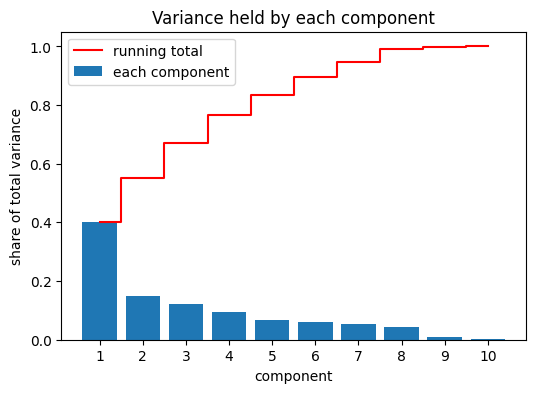

running total: [0.402 0.552 0.672 0.768 0.834 0.894 0.948 0.991 0.999 1.   ]


In [195]:
explained = s ** 2 / np.sum(s ** 2)       # share of the total variance held by each piece

plt.bar(range(1, 11), explained, label='each component')      # one bar per component, numbered 1 to 10
# np.cumsum gives the running total: first, first + second, first + second + third, and so on
plt.step(range(1, 11), np.cumsum(explained), where='mid', color='red', label='running total')
plt.xticks(range(1, 11))
plt.title('Variance held by each component')
plt.xlabel('component')
plt.ylabel('share of total variance')
plt.legend()
plt.show()

print('running total:', np.cumsum(explained))

The first component alone holds about 40% of the variation in all 10 measurements, and the last two hold almost nothing. The table has 10 columns, but the information in it has fewer real dimensions, because several measurements nearly repeat each other (the cholesterol columns in particular).

## 8.5 PCA is the SVD of standardized data

**Principal component analysis (PCA)** finds the perpendicular directions along which the data is most spread out, and describes each patient by coordinates along those directions.

PCA needs every column to have mean 0. We go one step further and use the standardized table `Z`, so that no measurement dominates just because of its units.

- The directions are the rows of `Vt`.
- The new coordinates, called **scores**, are `Z @ V`, which is the same as `U` times the singular values.

Z @ V equals U * s: True


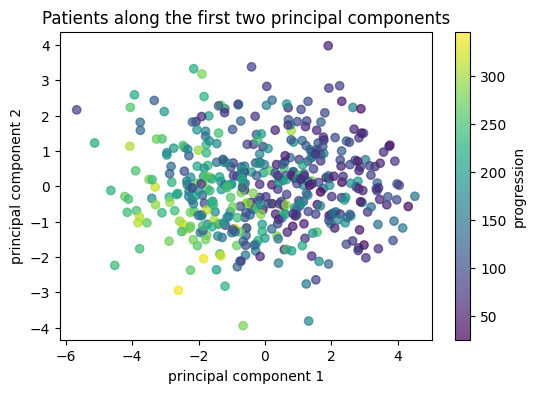

In [196]:
scores = Z @ Vt.T         # Vt.T is V. Each row of scores is one patient in the new coordinates

print('Z @ V equals U * s:', np.allclose(scores, U * s))

# Plot the first two score columns. c=y colours each dot by that patient's progression
plt.scatter(scores[:, 0], scores[:, 1], c=y, cmap='viridis', alpha=0.7)
plt.colorbar(label='progression')     # the scale that explains the colours
plt.title('Patients along the first two principal components')
plt.xlabel('principal component 1')
plt.ylabel('principal component 2')
plt.show()

In [197]:
# The first 2 rows of Vt, turned into columns and labelled with the measurement names
pd.DataFrame(Vt[:2].T, index=features, columns=['PC1', 'PC2'])

,PC1,PC2
age,-0.216,0.044
sex,-0.187,-0.387
bmi,-0.303,-0.156
bp,-0.272,-0.138
chol,-0.343,0.573
ldl,-0.352,0.456
hdl,0.282,0.506
chol_hdl,-0.429,-0.068
log_trig,-0.379,-0.026
glucose,-0.322,-0.085


The table shows how each measurement contributes to the first two components.

- In `PC1`, every measurement has the same sign except `hdl`. It is one combined score in which all the measurements move together and `hdl` moves the other way.
- In the plot, the colour changes steadily from one side to the other along component 1. So this single combined direction already carries much of the link with progression, even though PCA never looked at `y`.

The sign of a whole component is arbitrary: flipping all the signs of a row of `Vt` gives an equally valid answer.

scikit-learn's `PCA` does the same calculation:

In [198]:
from sklearn.decomposition import PCA

pca = PCA().fit(Z)        # scikit-learn's ready-made PCA, fitted on the same table

print('scikit-learn:', pca.explained_variance_ratio_)
print('our SVD:     ', explained)

scikit-learn: [0.402 0.149 0.121 0.096 0.066 0.06  0.054 0.043 0.008 0.001]
our SVD:      [0.402 0.149 0.121 0.096 0.066 0.06  0.054 0.043 0.008 0.001]


## 8.6 The pseudo-inverse and least squares

A matrix that is not square has no inverse, but the SVD gives the next best thing, the **pseudo-inverse**:

`A⁺ = V Σ⁻¹ Uᵀ`

(Inverting the diagonal `Σ` just means dividing by each singular value. A singular value of 0 would be skipped; our data has none.)

The least squares solution is `x̂ = A⁺ b`. This is what `np.linalg.lstsq` does inside, which closes the loop with Part 5.

In [199]:
U_r, s_r, Vt_r = np.linalg.svd(A_std, full_matrices=False)      # SVD of the regression matrix from Part 5

# x_hat = V Σ⁻¹ Uᵀ y, worked from right to left:
# Uᵀ y first, then divide by the singular values, then multiply by V
coef_svd = Vt_r.T @ ((U_r.T @ y) / s_r)

print('same coefficients as Part 5:', np.allclose(coef_svd, coef_std))
# np.linalg.pinv calculates the pseudo-inverse in one step
print('same as np.linalg.pinv:     ', np.allclose(np.linalg.pinv(A_std) @ y, coef_std))
print('largest / smallest singular value:', round(s_r[0] / s_r[-1], 4))
print('np.linalg.cond(A_std):            ', round(np.linalg.cond(A_std), 4))

same coefficients as Part 5: True
same as np.linalg.pinv:      True
largest / smallest singular value: 21.6813
np.linalg.cond(A_std):             21.6813


The last two lines match. That shows where the condition number of Part 5 comes from: it is the largest singular value divided by the smallest.

## Exercises for Part 8

1. Calculate the SVD of `[[1, 2], [3, 4], [5, 6]]` and rebuild the matrix from the three parts.
2. How many components are needed to hold at least 90% of the variance of `Z`?
3. Build the rank 1 approximation of the matrix from exercise 1 and print it next to the original.
4. Check that the first row of `Vt` equals the top eigenvector of `C` from Part 7 (`eigvecs_C[:, -1]`), apart from a possible flip of sign.

In [200]:
# Your code here


# Part 9: Mini project

## Predicting disease progression

**The question:** how well can the 10 measurements predict progression for patients the model has never seen, and how many principal components are really needed?

**The plan:**

1. Explore the data (Pandas)
2. Split it into a training set and a test set (NumPy)
3. Standardize the measurements (broadcasting, Part 1)
4. Fit a linear regression by least squares (Parts 4 and 5)
5. Measure how good the predictions are
6. Run an SVD on the training data (Part 8)
7. Fit the regression again using only the first few principal components
8. Write down what we found

## Step 1: Explore

rows and columns: (442, 11)
missing values:   0


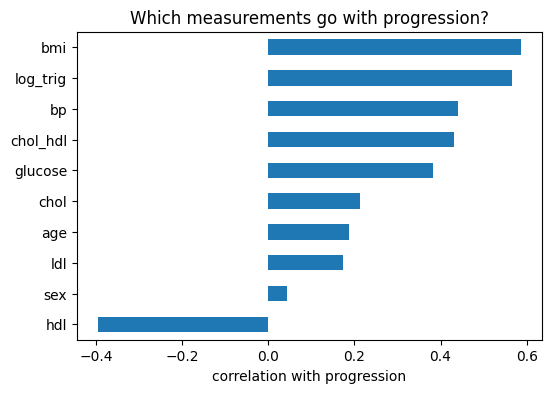

In [201]:
print('rows and columns:', df.shape)
print('missing values:  ', df.isna().sum().sum())

# Correlation of each measurement with progression, sorted and drawn as horizontal bars.
# drop removes the correlation of progression with itself, which is always 1
df.corr()['progression'].drop('progression').sort_values().plot.barh()
plt.title('Which measurements go with progression?')
plt.xlabel('correlation with progression')
plt.show()

## Step 2: Split into training and test sets

A model always looks good on the data it was fitted to. For an honest score, we fit on 80% of the patients (the training set) and measure on the other 20% (the test set), which the model never sees while fitting.

The `seed` fixes the random shuffle, so you get the same split every time you run the cell.

In [202]:
seed = 7
rng = np.random.default_rng(seed)         # random number generator; the seed makes it repeatable

order = rng.permutation(len(df))          # the row numbers in a random order
n_train = int(0.8 * len(df))              # 80% of 442, as a whole number: 353

train = df.iloc[order[:n_train]]          # the first 353 shuffled rows
test = df.iloc[order[n_train:]]           # the remaining 89 rows

# Turn each set into NumPy arrays: the measurements (X) and the value to predict (y)
X_train = train[features].to_numpy()
y_train = train['progression'].to_numpy()
X_test = test[features].to_numpy()
y_test = test['progression'].to_numpy()

print('training set:', X_train.shape, '  test set:', X_test.shape)

training set: (353, 10)   test set: (89, 10)


## Step 3: Standardize

The means and standard deviations are calculated from the **training set only** and then applied to both sets. The test set stands in for future patients, so nothing about it may be used while preparing the model.

In [203]:
mu = X_train.mean(axis=0)             # column means of the training set
sigma = X_train.std(axis=0)           # column standard deviations of the training set

Z_train = (X_train - mu) / sigma
Z_test = (X_test - mu) / sigma        # the test set uses the training means and spreads

print('training column means are all 0:', np.allclose(Z_train.mean(axis=0), 0))
print('test column means:    ', Z_test.mean(axis=0).round(3), '(close to 0, but not exactly)')

training column means are all 0: True
test column means:     [-0.139 -0.076 -0.009 -0.159 -0.08  -0.025 -0.109  0.045 -0.053 -0.093] (close to 0, but not exactly)


## Step 4: Fit by least squares

Three small functions keep the rest of the project short.

In [204]:
# Put a column of ones in front of the data (needed for the intercept)
def add_ones(data):
    return np.column_stack([np.ones(len(data)), data])

# Least squares: returns the intercept followed by one coefficient per column of data
def fit(data, target):
    return np.linalg.lstsq(add_ones(data), target, rcond=None)[0]

# Predictions: the matrix (with its ones column) times the coefficients
def predict(data, coefficients):
    return add_ones(data) @ coefficients

coef_train = fit(Z_train, y_train)       # fitted on the training set only
pd.Series(coef_train, index=['intercept'] + features).round(2)

intercept    153.88
age           -0.88
sex          -11.00
bmi           25.19
bp            16.74
chol         -37.72
ldl           18.63
hdl            7.48
chol_hdl      14.06
log_trig      33.40
glucose        3.20
dtype: float64

## Step 5: How good are the predictions?

Two scores:

- **R²** from Part 5.
- **RMSE** (root mean squared error): the typical size of a prediction error, in the same units as progression.

In [205]:
# Square the errors, take their mean, then take the square root
def rmse(actual, predicted):
    return np.sqrt(np.mean((actual - predicted) ** 2))

pred_train = predict(Z_train, coef_train)     # predictions for the patients the model was fitted on
pred_test = predict(Z_test, coef_train)       # predictions for the patients it has never seen

# A simple baseline to compare with: np.full makes an array in which every entry is the training average
always_average = np.full(len(y_test), y_train.mean())
print('RMSE on the test set if we always guess the training average:', round(rmse(y_test, always_average), 3))

# Collect the scores in a small table: one row for train, one row for test
results = pd.DataFrame({
    'R squared': [r_squared(y_train, pred_train), r_squared(y_test, pred_test)],
    'RMSE': [rmse(y_train, pred_train), rmse(y_test, pred_test)],
}, index=['train', 'test'])
results

RMSE on the test set if we always guess the training average: 79.501


,R squared,RMSE
train,0.525,52.634
test,0.477,57.155


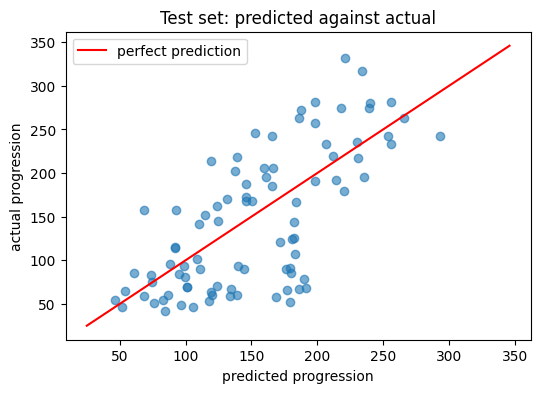

In [206]:
plt.scatter(pred_test, y_test, alpha=0.6)     # test patients only: predicted across, actual up
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', label='perfect prediction')
plt.xlabel('predicted progression')
plt.ylabel('actual progression')
plt.title('Test set: predicted against actual')
plt.legend()
plt.show()

## Step 6: SVD of the training data

As in Step 3, only the training set is used, so the test set stays unseen.

In [207]:
U_tr, s_tr, Vt_tr = np.linalg.svd(Z_train, full_matrices=False)      # SVD of the training set only
explained_tr = s_tr ** 2 / np.sum(s_tr ** 2)                         # share of the variance held by each component

print('running total of variance:', np.cumsum(explained_tr))

running total of variance: [0.399 0.546 0.668 0.763 0.832 0.893 0.948 0.992 0.999 1.   ]


## Step 7: Regression on the first k principal components

Instead of the 10 original columns, we use the scores along the first `k` principal directions as the inputs, for `k` from 1 to 10. The test set is projected onto the directions found from the training set.

In [208]:
rows = []                                # the results for each k are collected here
for k in range(1, 11):                   # k = 1, 2, ..., 10
    V_k = Vt_tr[:k].T                    # the first k directions, as columns
    T_train = Z_train @ V_k              # scores: k new columns
    T_test = Z_test @ V_k                # the test set, described along the same directions
    coef_k = fit(T_train, y_train)       # regression with the k score columns as inputs
    rows.append({                        # store the two scores for this k
        'components': k,
        'train R squared': r_squared(y_train, predict(T_train, coef_k)),
        'test R squared': r_squared(y_test, predict(T_test, coef_k)),
    })

# Turn the list into a table, with the number of components as the row label
pcr = pd.DataFrame(rows).set_index('components')
pcr

,train R squared,test R squared
components,,
1,0.297,0.335
2,0.347,0.331
3,0.389,0.345
4,0.509,0.470
5,0.510,0.468
6,0.514,0.470
7,0.521,0.475
8,0.521,0.477
9,0.522,0.472


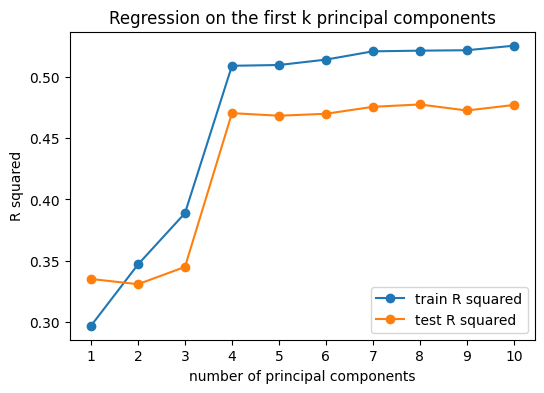

In [209]:
pcr.plot(marker='o')        # one line per column of the table, with a dot at each value
plt.xticks(range(1, 11))    # label every number of components from 1 to 10
plt.xlabel('number of principal components')
plt.ylabel('R squared')
plt.title('Regression on the first k principal components')
plt.show()

## Step 8: What we found

With `seed = 7`:

- **The model is useful but far from perfect.** On patients it has never seen, R² is about 0.48, and the typical error is about 57 points, against about 80 for always guessing the average. The 10 measurements explain roughly half of the variation in progression.
- **It is not just memorising.** The test score (0.48) is only a little below the training score (0.53).
- **Four components do the job of ten.** With the first 4 principal components the test R² is about 0.47, practically the same as with all 10 measurements. The remaining components add almost nothing.
- **The biggest component is not automatically the most useful.** The large jump comes when component 4 is added. PCA orders components by how much the measurements vary, without looking at progression at all.

One honest limit: with only 442 patients, these scores depend on which patients happen to land in the test set. With three other seeds (0, 1 and 42) the test R² came out at about 0.35, 0.43 and 0.59, so read 0.48 as a rough figure.

## Go further

1. Change `seed` in Step 2 and run Part 9 again. How much do the scores move?
2. Fit a model with only `bmi` and `log_trig`. How close does it get to the full model?
3. Plot the test residuals (`y_test - pred_test`) against `pred_test`. Do you see any pattern?
4. Leave `ldl` out and fit again. What happens to the coefficient of `chol`?

In [210]:
# Your code here


# How it all fits together

- A table of data is a matrix. Its rows and columns are vectors (Part 3).
- **Projection** finds the closest point in a column space (Part 4).
- **Least squares** is that projection applied to data, and gives linear regression (Part 5).
- The matrix `Aᵀ A` that appears there is symmetric, so it has perpendicular **eigenvectors** and can be **diagonalized** (Parts 6 and 7).
- **Factorizations** such as LU, QR and Cholesky are how computers solve these problems (Part 7).
- The **SVD** does for any matrix what eigenvectors do for symmetric ones. It gives PCA, compression and a safe way to do least squares (Part 8).

## Quick reference

| Task | Code |
|---|---|
| Dot product, matrix product | `a @ b`, `A @ B` |
| Length of a vector | `np.linalg.norm(a)` |
| Transpose | `A.T` |
| Solve a square system | `np.linalg.solve(A, b)` |
| Least squares | `np.linalg.lstsq(A, b, rcond=None)[0]` |
| Rank | `np.linalg.matrix_rank(A)` |
| Eigenvalues and eigenvectors | `np.linalg.eig(A)` |
| The same for a symmetric matrix | `np.linalg.eigh(S)` |
| LU | `scipy.linalg.lu(A)` |
| QR | `np.linalg.qr(A)` |
| Cholesky | `np.linalg.cholesky(S)` |
| SVD | `np.linalg.svd(A, full_matrices=False)` |
| Pseudo-inverse | `np.linalg.pinv(A)` |
| Condition number | `np.linalg.cond(A)` |

# Solutions to the exercises

Try each exercise yourself first. Run the whole notebook from the top before running these cells, because they use variables from the parts above.

In [211]:
# Part 1

# 1
tens = np.arange(10, 101, 10)      # stop at 101 so that 100 is included
print(tens, tens.shape)

# 2
age = X[:, 0]                      # all rows, column 0
print('youngest:', age.min(), ' oldest:', age.max(), ' average:', round(age.mean(), 2))

# 3
over_60 = age > 60                 # True or False for each patient
print('older than 60:', over_60.sum(), ' their average y:', round(y[over_60].mean(), 2))

# 4
y_standard = (y - y.mean()) / y.std()
# Rounding removes rounding leftovers, and + 0 stops a zero from being printed as -0.0
print('mean:', round(y_standard.mean(), 10) + 0, ' std:', round(y_standard.std(), 10))

[ 10  20  30  40  50  60  70  80  90 100] (10,)
youngest: 19.0  oldest: 79.0  average: 48.52
older than 60: 86  their average y: 176.27
mean: 0.0  std: 1.0


In [212]:
# Part 2

# 1: sorted by age, smallest first. display shows a table properly even when it is not the last line of a cell
display(df.sort_values('age').head(5))

# 2
print(df.groupby('sex')['bp'].mean())     # the mean of bp inside each sex group

# 3
people['bp_high'] = people['bp'] > 100
print('patients with bp above 100:', people['bp_high'].sum())      # sum counts the True values

# 4: look for the largest value away from the diagonal. It is chol with ldl (0.90).
display(df[features].corr().round(2))

,age,sex,bmi,bp,chol,ldl,hdl,chol_hdl,log_trig,glucose,progression
26,19.0,1.0,19.2,87.0,124.0,54.0,57.0,2.0,4.174,90.0,137.0
374,19.0,1.0,23.2,75.0,143.0,70.4,52.0,3.0,4.635,72.0,140.0
344,19.0,1.0,25.3,83.0,225.0,156.6,46.0,5.0,4.718,84.0,200.0
242,20.0,2.0,24.2,88.0,126.0,72.2,45.0,3.0,3.784,74.0,71.0
226,20.0,2.0,22.1,87.0,171.0,99.6,58.0,3.0,4.205,78.0,77.0


sex
1.0    91.522
2.0    98.195
Name: bp, dtype: float64
patients with bp above 100: 150


,age,sex,bmi,bp,chol,ldl,hdl,chol_hdl,log_trig,glucose
age,1.00,0.17,0.19,0.34,0.26,0.22,-0.08,0.20,0.27,0.30
sex,0.17,1.00,0.09,0.24,0.04,0.14,-0.38,0.33,0.15,0.21
bmi,0.19,0.09,1.00,0.40,0.25,0.26,-0.37,0.41,0.45,0.39
bp,0.34,0.24,0.40,1.00,0.24,0.19,-0.18,0.26,0.39,0.39
chol,0.26,0.04,0.25,0.24,1.00,0.90,0.05,0.54,0.52,0.33
ldl,0.22,0.14,0.26,0.19,0.90,1.00,-0.20,0.66,0.32,0.29
hdl,-0.08,-0.38,-0.37,-0.18,0.05,-0.20,1.00,-0.74,-0.40,-0.27
chol_hdl,0.20,0.33,0.41,0.26,0.54,0.66,-0.74,1.00,0.62,0.42
log_trig,0.27,0.15,0.45,0.39,0.52,0.32,-0.40,0.62,1.00,0.46
glucose,0.30,0.21,0.39,0.39,0.33,0.29,-0.27,0.42,0.46,1.00


In [213]:
# Part 3

# 1: 1*4 + 2*5 + 3*6 = 32
u3 = np.array([1, 2, 3])
v3 = np.array([4, 5, 6])
print('dot product:', u3 @ v3)

# 2
cos_uv = (u3 @ v3) / (np.linalg.norm(u3) * np.linalg.norm(v3))
print('angle in degrees:', round(np.degrees(np.arccos(cos_uv)), 2))

# 3: center both columns (subtract the mean), then use the cosine formula
chol_c = df['chol'].to_numpy() - df['chol'].mean()
ldl_c = df['ldl'].to_numpy() - df['ldl'].mean()
cos_chol_ldl = (chol_c @ ldl_c) / (np.linalg.norm(chol_c) * np.linalg.norm(ldl_c))
print('cosine:', round(cos_chol_ldl, 6), ' correlation:', round(df['chol'].corr(df['ldl']), 6))

# 4: x = 2, y = 3
# The matrix holds the numbers in front of x and y (1, 2 and 3, -1). The right-hand sides are 8 and 3
print('x and y:', np.linalg.solve(np.array([[1., 2.], [3., -1.]]), np.array([8., 3.])))

dot product: 32
angle in degrees: 12.93
cosine: 0.896663  correlation: 0.896663
x and y: [2. 3.]


In [214]:
# Part 4

# 1: [3, 0], the shadow of b on the horizontal axis
a4 = np.array([1., 0.])
b4 = np.array([3., 4.])
print('p =', (a4 @ b4) / (a4 @ a4) * a4)

# 2
a4 = np.array([1., 1., 1.])
b4 = np.array([1., 2., 3.])
p4 = (a4 @ b4) / (a4 @ a4) * a4
print('p =', p4, ' error @ a =', (b4 - p4) @ a4)

# 3: the two given vectors are the columns of A4
A4 = np.array([[1., 0.],
               [1., 1.],
               [1., 2.]])
P4 = A4 @ np.linalg.inv(A4.T @ A4) @ A4.T
print('P @ P equals P:', np.allclose(P4 @ P4, P4), ' projection:', P4 @ np.array([6., 0., 0.]))

# 4: about 10.2, the slope of the best-fit line in Part 5
print('x_hat =', round((bmi_c @ y_c) / (bmi_c @ bmi_c), 3))

p = [3. 0.]
p = [2. 2. 2.]  error @ a = 0.0
P @ P equals P: True  projection: [ 5.  2. -1.]
x_hat = 10.233


In [215]:
# Part 5

# 1: the same steps as in 5.1, with bp in place of bmi
bp = df['bp'].to_numpy()
A_bp = np.column_stack([np.ones(len(bp)), bp])
coef_bp = np.linalg.lstsq(A_bp, y, rcond=None)[0]
print('slope:', round(coef_bp[1], 3), ' R squared:', round(r_squared(y, A_bp @ coef_bp), 4))

# 2: yes, higher than the 0.34 of bmi alone
A_two = np.column_stack([np.ones(len(bp)), bmi, bp])      # three columns: ones, bmi, bp
coef_two = np.linalg.lstsq(A_two, y, rcond=None)[0]
print('R squared with bmi and bp:', round(r_squared(y, A_two @ coef_two), 4))

# 3: all zeros
print('A_full.T @ residuals:', np.round(A_full.T @ (y - A_full @ coef), 4) + 0)

# 4
print('prediction for bmi 30:', round(c + m * 30, 1))

slope: 2.461  R squared: 0.1949
R squared with bmi and bp: 0.396
A_full.T @ residuals: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
prediction for bmi 30: 189.2


In [216]:
# Part 6

# 1
G = np.array([[4., 1.],
              [2., 3.]])
g_values, g_vectors = np.linalg.eig(G)
print('eigenvalues:', g_values)
for i in range(2):
    print('G @ v =', G @ g_vectors[:, i], '   lambda * v =', g_values[i] * g_vectors[:, i])

# 2
print('with the eigenvalues:')
print(g_vectors @ np.diag(g_values ** 5) @ np.linalg.inv(g_vectors))
print('multiplied out directly:')
print(np.linalg.matrix_power(G, 5))

# 3: three quarters healthy, one quarter high
# Only the second column changes: 0.2 and 0.8 become 0.3 and 0.7
T_new = np.array([[0.9, 0.3],
                  [0.1, 0.7]])
new_values, new_vectors = np.linalg.eig(T_new)
steady_new = new_vectors[:, np.argmax(new_values)]
print('long-run split:', steady_new / steady_new.sum())

# 4: chol and ldl carry almost the same information (correlation 0.90), so nearly all
# of the spread lies along one direction and almost none across it.
pair = Z[:, [features.index('chol'), features.index('ldl')]]
print('eigenvalues for chol and ldl:', np.linalg.eigvalsh(pair.T @ pair / len(pair)))

eigenvalues: [5. 2.]
G @ v = [3.536 3.536]    lambda * v = [3.536 3.536]
G @ v = [-0.894  1.789]    lambda * v = [-0.894  1.789]
with the eigenvalues:
[[2094. 1031.]
 [2062. 1063.]]
multiplied out directly:
[[2094. 1031.]
 [2062. 1063.]]
long-run split: [0.75 0.25]
eigenvalues for chol and ldl: [0.103 1.897]


In [217]:
# Part 7

rng = np.random.default_rng(5)

# 1
G3 = rng.normal(size=(3, 3))       # a 3 by 3 matrix of random numbers
S3 = G3.T @ G3
print('symmetric:', np.allclose(S3, S3.T), ' eigenvalues:', np.linalg.eigvalsh(S3))

# 2: the two lengths are equal
Q_std, R_std = np.linalg.qr(A_std)
x11 = rng.normal(size=11)
print('length of x:', round(np.linalg.norm(x11), 6), ' length of Q @ x:', round(np.linalg.norm(Q_std @ x11), 6))

# 3
A7 = np.array([[4., 1.],
               [2., 3.]])
M7 = np.array([[1., 1.],
               [0., 2.]])
B7 = np.linalg.inv(M7) @ A7 @ M7       # similar to A7
print('eigenvalues of A:', np.sort(np.linalg.eigvals(A7)), ' of the similar matrix:', np.sort(np.linalg.eigvals(B7)))

# 4: already very close, because the largest eigenvalue is far ahead of the second one
v5 = np.ones(10)
for step in range(5):
    v5 = C @ v5
    v5 = v5 / np.linalg.norm(v5)
print('after 5 steps:', round(v5 @ C @ v5, 6), ' true value:', round(eigvals_C[-1], 6))

symmetric: True  eigenvalues: [0.036 0.637 4.748]
length of x: 3.5752  length of Q @ x: 3.5752
eigenvalues of A: [2. 5.]  of the similar matrix: [2. 5.]
after 5 steps: 4.024198  true value: 4.024211


In [218]:
# Part 8

# 1
B8 = np.array([[1., 2.],
               [3., 4.],
               [5., 6.]])
U8, s8, Vt8 = np.linalg.svd(B8, full_matrices=False)
print('rebuilt correctly:', np.allclose(U8 @ np.diag(s8) @ Vt8, B8))

# 2: the first position where the running total reaches 0.90 (+ 1 because positions start at 0)
print('components needed:', np.argmax(np.cumsum(explained) >= 0.90) + 1)

# 3: first singular value * (first column of U times first row of Vt), then the original below it
print('rank 1 approximation:')
print(s8[0] * np.outer(U8[:, 0], Vt8[0]))
print('original:')
print(B8)

# 4: np.abs removes the signs, so a flipped sign does not matter
print('same direction:', np.allclose(np.abs(Vt[0]), np.abs(eigvecs_C[:, -1])))

rebuilt correctly: True
components needed: 7
rank 1 approximation:
[[1.357 1.718]
 [3.097 3.923]
 [4.838 6.128]]
original:
[[1. 2.]
 [3. 4.]
 [5. 6.]]
same direction: True
